# IEEE-CIS Fraud Detection — ML R&D: от постановки задачи до воспроизводимого baseline

**Курс:** Исследования и разработка в ML (ML R&D)  
**Домашнее задание № 1:** постановка задачи, baseline, протокол оценки, воспроизводимость  
**Среда:** локальный Jupyter Notebook / Anaconda  
**Источник:** [IEEE-CIS Fraud Detection (Kaggle)](https://www.kaggle.com/competitions/ieee-fraud-detection/data)

## Цель и состав исследования

Цель - получить воспроизводимую точку отсчёта для ранжирования онлайн-транзакций по риску мошенничества и исследовать ограничения выбранной постановки. Рабочий ноутбук содержит:

1. Проверки источника, структуры и соединения таблиц `transaction` / `identity`.
2. Хронологическое разделение на обучение и локальную валидацию без использования целевой переменной.
3. EDA обучающей части: классы, пропуски, сумма, категории и временная динамика.
4. Обучение константного контрольного метода и логистической регрессии; метрики и анализ ошибок.
5. Недельную диагностику и три expanding-window проверки временной устойчивости.
6. Проверку воспроизведения baseline отдельными скриптами.
7. Контролируемую абляцию дополнительных полей `identity` на одинаковых внутренних фолдах.

**Статус:** перечисленные эксперименты выполнены на локальных данных. Зафиксированная основная метрика `baseline_v1` на хронологическом holdout - ROC-AUC = 0,749975. Этап абляции оценивается внутри обучающей части и не заменяет исходный baseline. Ограничения результатов приведены в соответствующих разделах.


## 0. Постановка задачи

**Прикладной контекст.** Для поступающей онлайн-транзакции требуется оценить риск мошенничества. Полученная оценка может служить основой последующих процедур проверки; самостоятельное принятие решения об отклонении платежа в исследовании не рассматривается.

| Компонент | Определение |
|---|---|
| Тип задачи | Бинарная классификация с оценкой вероятности положительного класса |
| Единица наблюдения | Отдельная транзакция, обозначенная `TransactionID` |
| Целевая переменная `y` | `isFraud`: 1 — мошенническая транзакция, 0 — обычная |
| Входные данные `X` | Пять транзакционных признаков в `baseline_v1`; дополнительные сведения `identity` — только в отдельном эксперименте |
| Одно предсказание | Значение `predict_proba(X)[:, 1]` в интервале от 0 до 1; калибровка не проверялась |
| Предполагаемый момент прогнозирования | Обработка текущей транзакции; фактическая доступность ряда анонимизированных признаков на этот момент не подтверждена |
| Основная метрика | ROC-AUC (метрика соревнования) |
| Дополнительная метрика | Average Precision (AP) по `average_precision_score`; показатель не тождественен трапециевидной площади под PR-кривой |

**Основная гипотеза H1.** Логистическая регрессия на ограниченном наборе транзакционных признаков обеспечивает ROC-AUC выше константного `DummyClassifier` на хронологически отложенном интервале. Основание — различия распределений характеристик транзакций между классами. Для проверки используется фиксированный holdout.

### Проверяемые исследовательские вопросы

1. **Устойчивость во времени (проверено).** Как отличаются ROC-AUC и AP между последовательно расположенными временными периодами при фиксированном baseline и при его переобучении в expanding-window схеме?
2. **Доступность `identity` (проверено).** Изменяются ли ROC-AUC, AP и Precision@1%, если к тем же признакам добавить только индикатор наличия записи `identity` (B против A) на идентичных временных фолдах?
3. **Поля `identity` (проверено).** Улучшают ли четыре характеристики идентификации и устройства ранжирование сверх индикатора наличия записи (C против B) при неизменной модели и временном протоколе?

**Дополнительный, не проверенный здесь вопрос:** насколько оценка при случайном стратифицированном разделении отличается от хронологической? Такое сравнение может служить диагностикой, но не заменяет проверку на будущих транзакциях.

### Ограничения

`TransactionDT` отражает количество секунд относительно неизвестной начальной даты; абсолютный календарный момент неизвестен. Семантика ряда анонимизированных полей, их доступность в момент авторизации и механизм получения меток мошенничества документированы не полностью. Кодированные характеристики карты не считаются надёжными идентификаторами клиента без отдельного подтверждения.

**Происхождение решения.** Исследование использует исходные данные Kaggle и стандартные библиотеки Python; готовые чужие Kaggle-ноутбуки не использованы. Для проектирования структуры, подготовки текста и части кода применялся ChatGPT (OpenAI); результаты измерены локально и проверены исполняемыми скриптами. Подробности — в README.


## 1. Среда выполнения и источник данных

Исследование выполняется в локальном Jupyter Notebook под управлением Anaconda. Доступ к Kaggle API, Colab и Google Drive во время запуска не требуется.

### Размещение файлов

```text
ieee-fraud-detection/
├── IEEE_Fraud_EDA.ipynb
├── README.md
├── requirements.txt
├── .gitignore
├── ieee-fraud-detection.zip       # локально, исключается из Git
├── configs/
│   ├── baseline.json
│   └── identity_ablation.json
├── src/
│   ├── __init__.py
│   ├── utils.py
│   ├── train.py
│   ├── evaluate.py
│   └── identity_ablation.py
├── scripts/
│   ├── run_baseline.bat
│   └── run_baseline.sh
├── results/                       # агрегированные метрики, графики
└── artifacts/                     # локальные модели, исключаются из Git
```

Имя архива по умолчанию — `ieee-fraud-detection.zip`. **Распаковка не требуется:** необходимые CSV читаются непосредственно из ZIP. Относительные пути вычисляются от `Path.cwd()`, поэтому запуск должен выполняться из каталога проекта либо путь `ARCHIVE_PATH` следует изменить.

Зависимости перечислены в `requirements.txt`; установка пакетов непосредственно из ноутбука не выполняется. Исследовательский ноутбук дополняется отдельными скриптами обучения и оценки для воспроизводимости.


In [1]:
from pathlib import Path, PurePosixPath
from contextlib import contextmanager
import json
import platform
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

# Путь к ZIP задаётся относительно рабочего каталога Jupyter.
# При необходимости допускается абсолютный путь, например Path(r"D:\data\ieee-fraud-detection.zip").
ARCHIVE_PATH = Path("ieee-fraud-detection.zip")

# Папка для агрегированных результатов; исходные данные не копируются.
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_NAMES = ("train_transaction.csv", "train_identity.csv")

print("Каталог проекта:", Path.cwd().name)
print("Имя архива:", ARCHIVE_PATH.name)

if not ARCHIVE_PATH.is_file():
    available_archives = sorted(p.name for p in Path.cwd().glob("*.zip"))
    raise FileNotFoundError(
        f"Архив не найден: {ARCHIVE_PATH.resolve()}. "
        f"ZIP-файлы в рабочем каталоге: {available_archives}. "
        "Проверьте имя архива или измените ARCHIVE_PATH."
    )

if not zipfile.is_zipfile(ARCHIVE_PATH):
    raise ValueError(f"Файл не является корректным ZIP-архивом: {ARCHIVE_PATH}")

print("Размер ZIP, МБ:", round(ARCHIVE_PATH.stat().st_size / 1024**2, 1))
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "numpy:", np.__version__, "matplotlib:", matplotlib.__version__)

Каталог проекта: HW1
Имя архива: ieee-fraud-detection.zip
Размер ZIP, МБ: 118.1
Python: 3.12.4
pandas: 2.2.2 numpy: 1.26.4 matplotlib: 3.8.4


### 1.1. Чтение CSV непосредственно из ZIP

Библиотека `zipfile` предоставляет доступ к отдельным файлам внутри архива без предварительной распаковки. При вызове `pd.read_csv` содержимое нужного CSV последовательно распаковывается в память, поэтому объём оперативной памяти по-прежнему зависит от числа загружаемых столбцов.

Далее выполняется проверка наличия двух обязательных обучающих файлов. Тестовые файлы соревнования для локального EDA и обучения baseline не используются.

In [2]:
@contextmanager
def open_csv(filename: str):
    """Предоставляет двоичный поток указанного CSV внутри ZIP-архива."""
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
        matches = [
            member.filename for member in archive.infolist()
            if not member.is_dir() and PurePosixPath(member.filename).name == filename
        ]
        if len(matches) != 1:
            raise FileNotFoundError(
                f"В ZIP найдено {len(matches)} файлов с именем {filename}; "
                "ожидается ровно один."
            )
        with archive.open(matches[0], "r") as stream:
            yield stream


# Проверяется наличие и схема только двух обучающих таблиц.
for filename in DATA_NAMES:
    with open_csv(filename) as stream:
        column_names = pd.read_csv(stream, nrows=0).columns.tolist()
    print(f"{filename}: {len(column_names)} столбцов")
    print("Первые 12 столбцов:", column_names[:12])
    print()

train_transaction.csv: 394 столбцов
Первые 12 столбцов: ['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1']

train_identity.csv: 41 столбцов
Первые 12 столбцов: ['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11']



## 2. Выбор столбцов для первичного EDA

Исходная таблица транзакций включает несколько сотен признаков. На первом этапе исследуется ограниченный, заранее определённый набор: это сокращает расход оперативной памяти и обеспечивает проверку основных свойств данных до полного анализа.

**Используемые группы столбцов:**

- Идентификатор и временная координата: `TransactionID`, `TransactionDT`.
- Целевая переменная: `isFraud`.
- Характеристики транзакции и платёжной карты: `TransactionAmt`, `ProductCD`, `card1`–`card6`.
- Контактные и географические характеристики: `addr1`, `addr2`, `P_emaildomain`, `R_emaildomain`.
- Часть анонимизированных полей: `C1`, `C2`, `D1`, `D2`, `M1`–`M4`, `dist1`, `dist2`.
- Дополнительные поля `identity`: `DeviceType`, `DeviceInfo`, `id_12`, `id_15`, `id_31`, `id_33`.

Семантика полей `C*`, `D*`, `M*`, `id_*` частично скрыта организатором соревнования. Бизнес-интерпретация этих столбцов без подтверждения первоисточником не предполагается. Проверка доли пропусков по всем полям выделена в отдельный необязательный этап.

In [3]:
TRANSACTION_COLUMNS = [
    "TransactionID", "TransactionDT", "TransactionAmt", "isFraud",
    "ProductCD", "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "P_emaildomain", "R_emaildomain",
    "dist1", "dist2", "C1", "C2", "D1", "D2",
    "M1", "M2", "M3", "M4",
]

IDENTITY_COLUMNS = [
    "TransactionID", "DeviceType", "DeviceInfo",
    "id_12", "id_15", "id_31", "id_33",
]

# Загрузка ограничена выбранными столбцами; исходные CSV остаются внутри ZIP.
with open_csv("train_transaction.csv") as stream:
    transactions = pd.read_csv(
        stream,
        usecols=TRANSACTION_COLUMNS,
        low_memory=False,
    )

with open_csv("train_identity.csv") as stream:
    identity = pd.read_csv(
        stream,
        usecols=IDENTITY_COLUMNS,
        low_memory=False,
    )

print("Транзакции (число строк, выбранные столбцы):", transactions.shape)
print("Identity (число строк, выбранные столбцы):", identity.shape)
print("Память transactions, МБ:",
      round(transactions.memory_usage(deep=True).sum() / 1024**2, 1))
print("Память identity, МБ:",
      round(identity.memory_usage(deep=True).sum() / 1024**2, 1))

# Для публикации отображаются только агрегированные характеристики.
# Примеры отдельных транзакций не выводятся.


Транзакции (число строк, выбранные столбцы): (590540, 25)
Identity (число строк, выбранные столбцы): (144233, 7)
Память transactions, МБ: 308.0
Память identity, МБ: 46.2


## 3. Контроль качества исходных данных и соединения таблиц

**Проверяемое условие:** `TransactionID` должен однозначно идентифицировать запись транзакции. Если соответствующий ключ в таблице `identity` повторяется, обычный `LEFT JOIN` может размножить строки и исказить дальнейший анализ.

Проверяются:

1. Количество записей и уникальных значений `TransactionID` в каждой таблице.
2. Пропуски в ключах и целевой переменной.
3. Число записей `identity`, не сопоставимых с обучающими транзакциями.
4. Сохранение числа транзакций после `LEFT JOIN` с проверкой `validate="one_to_one"`.

При нарушении проверок `assert` выполнение останавливается. Автоматическое удаление дубликатов не предусмотрено: сначала необходим анализ их происхождения.

In [4]:
quality = pd.DataFrame({
    "таблица": ["transactions", "identity"],
    "строк": [len(transactions), len(identity)],
    "уникальных TransactionID": [
        transactions["TransactionID"].nunique(dropna=False),
        identity["TransactionID"].nunique(dropna=False),
    ],
    "пропусков TransactionID": [
        transactions["TransactionID"].isna().sum(),
        identity["TransactionID"].isna().sum(),
    ],
    "дубликатов TransactionID": [
        transactions["TransactionID"].duplicated().sum(),
        identity["TransactionID"].duplicated().sum(),
    ],
})
display(quality)

print("Пропущенных isFraud:", transactions["isFraud"].isna().sum())
print("Возможные значения isFraud:",
      sorted(transactions["isFraud"].dropna().unique().tolist()))

only_identity_ids = (~identity["TransactionID"].isin(
    transactions["TransactionID"])).sum()
print("Identity без соответствующей train-транзакции:", only_identity_ids)

assert transactions["TransactionID"].is_unique, "Найдены дубли ключей транзакций"
assert identity["TransactionID"].is_unique, "Найдены дубли ключей identity"
assert not transactions["TransactionID"].isna().any()
assert not transactions["isFraud"].isna().any()
assert set(transactions["isFraud"].unique()) <= {0, 1}

joined = transactions.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one",
    indicator=True,
)
joined["has_identity"] = joined["_merge"].eq("both")

print("Строк после LEFT JOIN:", len(joined))
print("Транзакций с записью identity:", int(joined["has_identity"].sum()))
print("Доля транзакций с identity:", f"{joined['has_identity'].mean():.2%}")
assert len(joined) == len(transactions)

joined.drop(columns=["_merge"], inplace=True)

,таблица,строк,уникальных TransactionID,пропусков TransactionID,дубликатов TransactionID
0,transactions,590540,590540,0,0
1,identity,144233,144233,0,0


Пропущенных isFraud: 0
Возможные значения isFraud: [0, 1]
Identity без соответствующей train-транзакции: 0
Строк после LEFT JOIN: 590540
Транзакций с записью identity: 144233
Доля транзакций с identity: 24.42%


### 3.1. Результаты проверки соединения

| Проверка | Фактический результат | Вывод |
|---|---:|---|
| Объём `train_transaction.csv` | 590 540 строк | Объекты исследования — транзакции |
| Объём `train_identity.csv` | 144 233 строки | Дополнительная информация доступна не для всех транзакций |
| Дубликаты `TransactionID` в обеих таблицах | 0 | Условия однозначного соединения по ключу соблюдены |
| Пропуски `TransactionID` в обеих таблицах | 0 | Отсутствующих ключей не выявлено |
| Записи `identity`, не сопоставленные с обучающими транзакциями | 0 | Все загруженные `identity` относятся к train-транзакциям |
| Объём результата `LEFT JOIN` | 590 540 строк | Число транзакций сохранено; размножение объектов отсутствует |
| Доля транзакций с записью `identity` на полном исходном train | 24,42% | Пропуски дополнительных полей имеют структурную причину |

**Интерпретация.** Проверена корректность ключевого соединения двух таблиц в пределах выбранных полей. `LEFT JOIN` сохраняет транзакции без дополнительных данных. Пропуски в полях `identity` не следует отождествлять с ошибками соединения.

**Ограничение.** Уникальность ключей не доказывает отсутствие зависимых транзакций, относящихся к одной карте или клиенту; задача групповой независимости рассматривается отдельно.

## 4. Фиксация протокола локальной валидации до содержательного EDA

Основной протокол — **хронологический holdout**: приблизительно первые 80% транзакций по `TransactionDT` относятся к обучающей части, последующие 20% — к валидационной. Граница определяется по временной координате без использования целевой переменной.

**Обоснование.** При прогнозировании риска будущих операций обучающие данные должны предшествовать проверяемому периоду. Случайное разделение строк способно переоценивать качество при временном дрейфе характеристик и целевой переменной.

**Допущения и ограничения:**

- `TransactionDT` — относительное время в секундах; известной календарной даты начала отсчёта нет.
- Транзакции с одинаковым временем относятся к одной части выборки.
- Хронологический split не исключает полностью зависимость через повторяющиеся платёжные сущности; соответствующий риск документируется отдельно.
- Все обучаемые преобразования (заполнение пропусков, масштабирование, кодирование категорий) впоследствии подгоняются только на train.
- Kaggle test не используется для локальной оценки.

После определения границы содержательные распределения целевой переменной и анализ признаков выполняются исключительно на обучающей части. Валидационные метки резервируются для итоговой оценки моделей.

In [5]:
assert joined["TransactionDT"].notna().all(), "Есть пропуски TransactionDT"

# Квантиль (80%) вычисляется только по временной координате.
CUTOFF_DT = joined["TransactionDT"].quantile(0.80)

train_df = joined.loc[joined["TransactionDT"] < CUTOFF_DT].copy()
val_df = joined.loc[joined["TransactionDT"] >= CUTOFF_DT].copy()

assert len(train_df) > 0 and len(val_df) > 0
assert len(train_df) + len(val_df) == len(joined)
assert train_df["TransactionDT"].max() < val_df["TransactionDT"].min()

split_summary = pd.DataFrame({
    "выборка": ["train", "validation"],
    "строк": [len(train_df), len(val_df)],
    "доля всех строк, %": [
        100 * len(train_df) / len(joined),
        100 * len(val_df) / len(joined),
    ],
    "минимум TransactionDT": [
        train_df["TransactionDT"].min(), val_df["TransactionDT"].min(),
    ],
    "максимум TransactionDT": [
        train_df["TransactionDT"].max(), val_df["TransactionDT"].max(),
    ],
})
display(split_summary)
print("Граница разделения TransactionDT:", CUTOFF_DT)
print("Общий диапазон, дней:", round(
    (joined["TransactionDT"].max() - joined["TransactionDT"].min()) / 86400, 1
))

,выборка,строк,"доля всех строк, %",минимум TransactionDT,максимум TransactionDT
0,train,472432,80.0,86400,12192842
1,validation,118108,20.0,12192900,15811131


Граница разделения TransactionDT: 12192853.600000001
Общий диапазон, дней: 182.0


### 4.1. Фактически полученное временное разделение

| Часть данных | Число транзакций | Доля | Диапазон `TransactionDT` |
|---|---:|---:|---:|
| Train | 472 432 | 80% | 86 400–12 192 842 |
| Validation | 118 108 | 20% | 12 192 900–15 811 131 |

Граница рассчитана по квантилю временного признака: `CUTOFF_DT = 12 192 853,6`. Максимальное время обучающей части меньше минимального времени валидации. Разделение выполнялось без использования `isFraud`.

**Методологический вывод.** Валидация имитирует предсказание на более поздних событиях. Это не гарантирует независимость наблюдений, если транзакции относятся к повторяющимся клиентам или картам. Метки валидации не используются для EDA и выбора признаков до фиксации baseline.

## 5. Разведочный анализ обучающей выборки

Все приведённые далее статистики относятся к `train_df`, если не указано иное. Анализ валидационных меток до завершения постановки baseline не проводится.

### 5.1. Целевая переменная и дисбаланс классов

Для редкого положительного класса Accuracy может давать чрезмерно оптимистичную оценку. Константное предсказание класса `0` может обеспечить высокую Accuracy и одновременно нулевую полноту обнаружения мошенничества.

**Задача анализа:** определить число транзакций каждого класса, их доли и достаточность числа положительных объектов для локальной оценки.

,isFraud,количество,"доля, %"
0,0,455833,96.486478
1,1,16599,3.513522


Доля мошенничества на train: 3.5135%
Ожидаемая Accuracy константной модели, всегда предсказывающей 0: 96.4865%


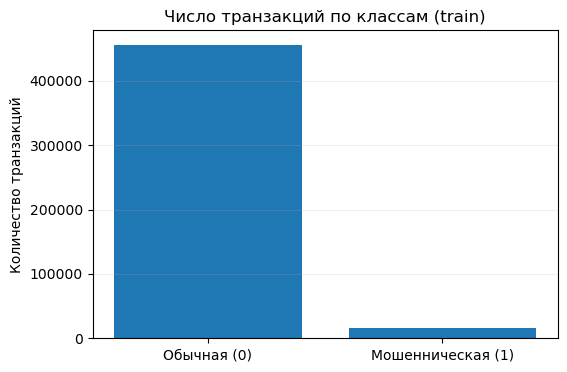

In [6]:
target_table = (
    train_df["isFraud"]
    .value_counts(dropna=False)
    .rename_axis("isFraud")
    .reset_index(name="количество")
)
target_table["доля, %"] = (
    100 * target_table["количество"] / len(train_df)
)
display(target_table)

fraud_rate_train = float(train_df["isFraud"].mean())
print(f"Доля мошенничества на train: {fraud_rate_train:.4%}")
print("Ожидаемая Accuracy константной модели, всегда предсказывающей 0:",
      f"{1 - fraud_rate_train:.4%}")

plt.figure(figsize=(6, 4))
counts = train_df["isFraud"].value_counts().sort_index()
plt.bar(["Обычная (0)", "Мошенническая (1)"], counts.values)
plt.ylabel("Количество транзакций")
plt.title("Число транзакций по классам (train)")
plt.grid(axis="y", alpha=0.2)
plt.show()

### 5.1.1. Интерпретация распределения классов

В обучающей выборке содержится 455 833 обычных (96,49%) и 16 599 мошеннических (3,51%) транзакций. Положительный класс существенно реже отрицательного.

Для постоянного предсказания класса `0` Accuracy **на обучающей выборке** составила бы 96,49%, но полнота (Recall) по мошенническому классу равнялась бы нулю. Эта величина — характеристика дисбаланса, а не вычисленная метрика обученного baseline.

**Следствие для протокола:** основная метрика — ROC-AUC (согласно условию соревнования), дополнительная — Average Precision (AP), позволяющая оценить качество ранжирования при редком положительном классе. Для константной вероятности ROC-AUC равна 0,5 при наличии обоих классов; фактические метрики baseline на validation пока не вычислены.

### 5.2. Типы признаков и пропущенные значения

Пропуски могут иметь различное происхождение: техническую недоступность значения, отсутствие дополнительной записи `identity` или особенности формирования признака. Высокая доля пропусков сама по себе не является достаточным основанием для удаления поля.

Рассматриваются:

- число и доля пропусков;
- число различных непустых значений;
- различие между числовым типом хранения и категориальной природой признака (например, `card1`);
- особенности отсутствующей информации `identity`.

На этом этапе не выполняются заполнение пропусков и другие преобразования, требующие оценки параметров. Параметры предобработки в дальнейшем вычисляются исключительно на обучающей выборке.

,тип,число пропусков,"доля пропусков, %",уникальных без NaN
dist2,float64,440332,93.21,1664
id_33,object,410619,86.92,212
DeviceInfo,object,372896,78.93,1639
R_emaildomain,object,358812,75.95,60
id_31,object,354969,75.14,110
DeviceType,object,354794,75.10,2
id_15,object,354636,75.07,3
id_12,object,351968,74.50,2
dist1,float64,287157,60.78,2589
M1,object,238295,50.44,2


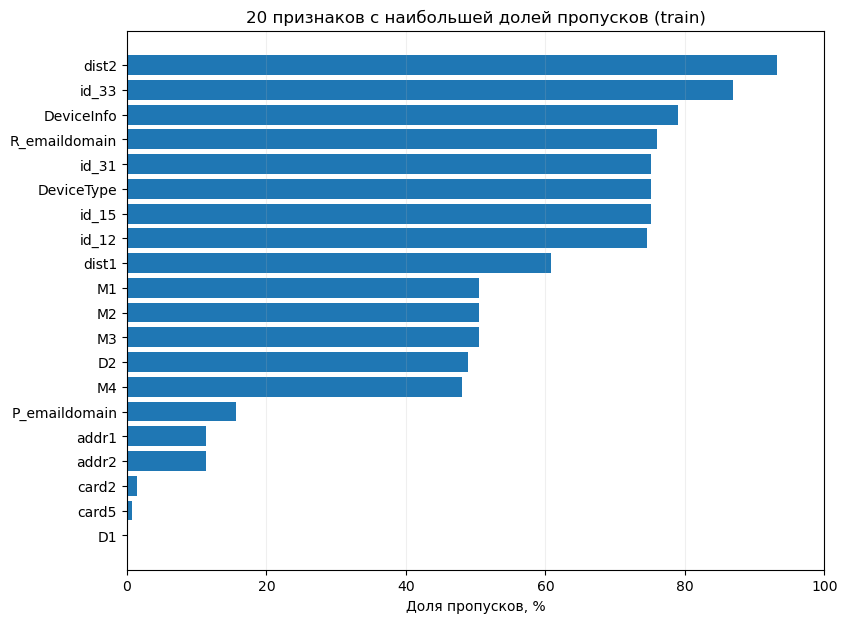

In [7]:
feature_cols = [
    c for c in train_df.columns
    if c not in ("TransactionID", "isFraud", "TransactionDT", "has_identity")
]

missing_table = pd.DataFrame({
    "тип": train_df[feature_cols].dtypes.astype(str),
    "число пропусков": train_df[feature_cols].isna().sum(),
    "доля пропусков, %": 100 * train_df[feature_cols].isna().mean(),
    "уникальных без NaN": train_df[feature_cols].nunique(dropna=True),
}).sort_values("доля пропусков, %", ascending=False)

display(missing_table.round(2))

plot_missing = missing_table.head(20).sort_values("доля пропусков, %")
plt.figure(figsize=(9, 7))
plt.barh(plot_missing.index, plot_missing["доля пропусков, %"])
plt.xlabel("Доля пропусков, %")
plt.title("20 признаков с наибольшей долей пропусков (train)")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.2)
plt.show()

### 5.2.1. Интерпретация пропусков и типов

На обучающей выборке наиболее высокая доля пропусков выявлена у `dist2` (93,21%), `id_33` (86,92%), `DeviceInfo` (78,93%), `R_emaildomain` (75,95%) и `DeviceType` (75,10%). Отдельные признаки, в том числе `TransactionAmt`, `ProductCD`, `card1`, `C1` и `C2`, пропусков не содержат.

Поля с префиксом `id_` и характеристики устройства относятся к дополнительной таблице `identity`, доступной только для части операций. Вместе с тем высокая доля пропусков у `dist2` и `R_emaildomain` показывает, что неполнота данных встречается и в транзакционных полях.

**Следствие для baseline:** пропуски следует обрабатывать внутри обучаемого `Pipeline`: медианой для числовых признаков и отдельной категорией для категориальных. Числовой тип хранения не означает, что признак количественный (`card1` и другие `card*` могут представлять кодированные категории).

**Ограничение:** исследованы только выбранные для первичного EDA признаки. Проверка полноты всех 394 столбцов `train_transaction.csv` предусмотрена отдельно и по умолчанию отключена.

### 5.3. Распределение сумм транзакций

`TransactionAmt` описывает величину транзакции; конкретная валюта не предполагается без подтверждения в документации. Для каждого класса рассчитываются основные описательные статистики и квантили.

Для визуализации применяется `log1p(TransactionAmt)`: такое преобразование уменьшает влияние большого диапазона сумм на масштаб графика. В этой версии логарифм применяется **только для построения графика**, а не для обучения модели.

Различия распределений по классам не являются доказательством причинной связи или гарантией прогностической полезности признака.

,count,min,median,mean,max
isFraud,,,,,
0,455833,0.25,68.50,133.87,31937.39
1,16599,0.29,76.13,149.04,5191.00


Квантили суммы на train:


0.00        0.251
0.25       42.950
0.50       68.950
0.75      125.000
0.95      441.950
0.99     1104.000
1.00    31937.391
Name: TransactionAmt, dtype: float64

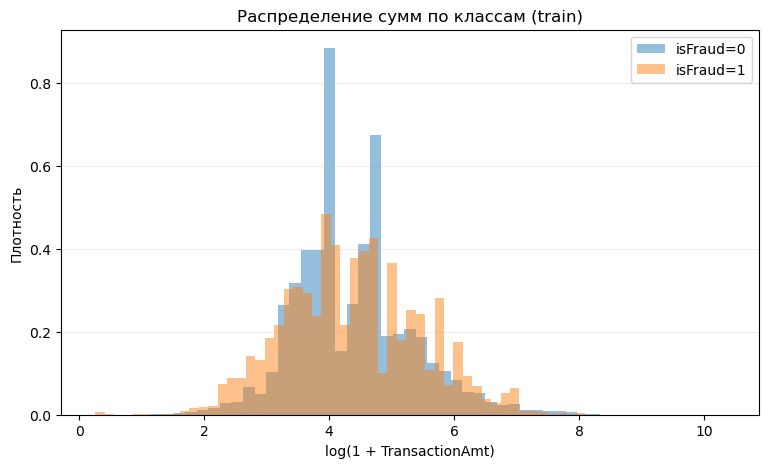

In [8]:
amount_stats = train_df.groupby("isFraud")["TransactionAmt"].agg(
    ["count", "min", "median", "mean", "max"]
)
display(amount_stats.round(2))

print("Квантили суммы на train:")
display(train_df["TransactionAmt"].quantile([0, .25, .5, .75, .95, .99, 1]))

assert (train_df["TransactionAmt"].dropna() >= 0).all(), (
    "Найдены отрицательные суммы — нужно отдельно проверить источник"
)

# Логарифм — только способ визуализации, не обучаемая трансформация.
plt.figure(figsize=(9, 5))
for cls in (0, 1):
    values = np.log1p(
        train_df.loc[
            train_df["isFraud"] == cls, "TransactionAmt"
        ].dropna().to_numpy()
    )
    plt.hist(values, bins=55, density=True, alpha=0.48, label=f"isFraud={cls}")

plt.xlabel("log(1 + TransactionAmt)")
plt.ylabel("Плотность")
plt.title("Распределение сумм по классам (train)")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.show()

### 5.3.1. Интерпретация распределений сумм

Медиана `TransactionAmt` в обучающей части составляет 68,50 для класса `0` и 76,13 для класса `1`; средние значения — 133,87 и 149,04 соответственно. Максимальные суммы существенно выше медианных значений, что указывает на длинный правый хвост распределения.

После преобразования `log1p(TransactionAmt)` распределения двух классов заметно перекрываются. Следовательно, даже при наличии различий в описательных статистиках **сумма транзакции сама по себе не разделяет классы однозначно**.

**Следствие для baseline:** `TransactionAmt` включается как потенциально полезный числовой признак; влияние масштабирования и преобразования определяется в рамках обучаемого конвейера, без использования статистик validation.


### 5.4. Временная динамика транзакций

`TransactionDT` определяет порядок событий и относительную продолжительность наблюдений, но не позволяет установить действительные календарные даты без известной начальной точки.

Данные обучающей части агрегируются по непересекающимся интервалам продолжительностью семь суток от первого наблюдения в train. Для каждого интервала вычисляются:

1. Число транзакций.
2. Число мошеннических транзакций.
3. Доля мошеннических транзакций.

Наблюдаемая временная неоднородность может указывать на смещение распределений и усиливать аргументацию в пользу хронологической оценки. При этом график не доказывает существования определённой причины изменений.

,relative_week,n_transactions,n_fraud,fraud_rate
0,0,27596,804,0.029135
1,1,28463,717,0.025191
2,2,35701,869,0.024341
3,3,34906,724,0.020741
4,4,24539,889,0.036228
5,5,20919,803,0.038386
6,6,20564,823,0.040021
7,7,19761,862,0.043621
8,8,21432,927,0.043253
9,9,22534,996,0.044200


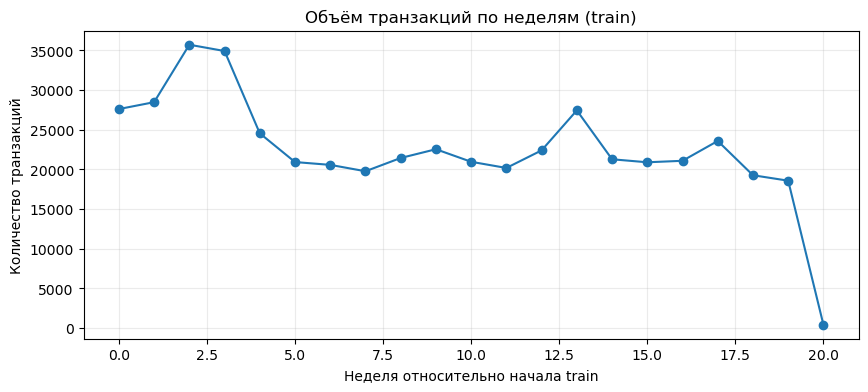

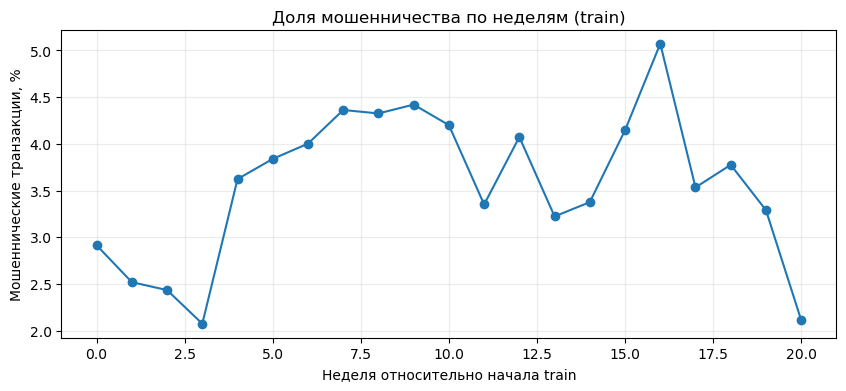

In [9]:
start_dt = train_df["TransactionDT"].min()
week_index = ((train_df["TransactionDT"] - start_dt) // (7 * 86400)).astype(int)

weekly = (
    train_df.assign(relative_week=week_index)
    .groupby("relative_week", as_index=False)
    .agg(
        n_transactions=("isFraud", "size"),
        n_fraud=("isFraud", "sum"),
        fraud_rate=("isFraud", "mean"),
    )
)
display(weekly)

plt.figure(figsize=(10, 4))
plt.plot(weekly["relative_week"], weekly["n_transactions"], marker="o")
plt.xlabel("Неделя относительно начала train")
plt.ylabel("Количество транзакций")
plt.title("Объём транзакций по неделям (train)")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(weekly["relative_week"], 100 * weekly["fraud_rate"], marker="o")
plt.xlabel("Неделя относительно начала train")
plt.ylabel("Мошеннические транзакции, %")
plt.title("Доля мошенничества по неделям (train)")
plt.grid(alpha=0.25)
plt.show()

### 5.4.1. Интерпретация временной динамики

Внутри обучающей части объём транзакций и доля мошенничества неоднородны по относительным неделям. Например, наблюдаемая доля мошенничества варьируется примерно от 2,07% на неделе 3 до 5,07% на неделе 16 (по границам недель, принятым в коде).

Последняя отображаемая неделя с индексом `20` содержит только **426 транзакций**, поскольку заканчивается на границе хронологического train. Она является **неполной**, поэтому падение количества транзакций и доли мошенничества на ней нельзя интерпретировать как полноценный недельный тренд.

**Вывод:** структура данных допускает временную неоднородность, а хронологический holdout является содержательно обоснованным. График сам по себе не позволяет определить причины изменений; для оценки временной устойчивости потребуются отдельные интервалы проверки.

### 5.5. Категориальные признаки и неоднородность доли мошенничества

Для `ProductCD`, `card4` и `card6` рассчитываются частоты категорий и доля класса `isFraud=1` в каждой категории.

Доли, полученные для малочисленных групп, могут иметь высокую случайную изменчивость. Поэтому отдельно отображаются категории с числом наблюдений не меньше заданного порога `MIN_GROUP_SIZE`. Этот порог — описательная эвристика, а не статистический критерий значимости.

Вычисленные по целевой переменной частоты не включаются в признаки модели. Использование таких частот без разделения на обучающую и проверочную части создало бы утечку целевой переменной.

In [10]:
MIN_GROUP_SIZE = 200  # Порог только для устойчивости описательной таблицы EDA.

for column in ["ProductCD", "card4", "card6"]:
    group = (
        train_df.assign(category=train_df[column].astype("string").fillna("<пропуск>"))
        .groupby("category", as_index=False)
        .agg(n=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
        .sort_values("n", ascending=False)
    )
    print(f"\nПризнак {column} — самые частые категории:")
    display(group.head(12).round(4))

    reliable_groups = group.loc[group["n"] >= MIN_GROUP_SIZE]
    if not reliable_groups.empty:
        print(f"{column}: категории с >= {MIN_GROUP_SIZE} наблюдений, по fraud_rate:")
        display(reliable_groups.sort_values("fraud_rate", ascending=False).head(10).round(4))


Признак ProductCD — самые частые категории:


,category,n,fraud_rate
4,W,346001,0.0207
0,C,56410,0.1133
2,R,32203,0.0363
1,H,29691,0.0464
3,S,8127,0.0619


ProductCD: категории с >= 200 наблюдений, по fraud_rate:


,category,n,fraud_rate
0,C,56410,0.1133
3,S,8127,0.0619
1,H,29691,0.0464
2,R,32203,0.0363
4,W,346001,0.0207



Признак card4 — самые частые категории:


,category,n,fraud_rate
4,visa,308141,0.0347
3,mastercard,150862,0.0349
1,american express,7202,0.0286
2,discover,5394,0.0743
0,<пропуск>,833,0.0312


... (2 outputs left out)


Признак card6 — самые частые категории:


,category,n,fraud_rate
3,debit,349843,0.0240
2,credit,121716,0.0673
0,<пропуск>,828,0.0290
4,debit or credit,30,0.0000
1,charge card,15,0.0000


card6: категории с >= 200 наблюдений, по fraud_rate:


,category,n,fraud_rate
2,credit,121716,0.0673
0,<пропуск>,828,0.0290
3,debit,349843,0.0240


### 5.5.1. Интерпретация категориальных распределений

В обучающей выборке для `ProductCD` наблюдаются разные доли мошенничества: категория `W` — 2,07% при 346 001 транзакции, категория `C` — 11,33% при 56 410 транзакциях. Для `card6` доля мошенничества составляет 2,40% в категории `debit` (349 843 наблюдения) и 6,73% в категории `credit` (121 716 наблюдений).

Различия заметны при достаточно больших объёмах указанных категорий, однако могут быть связаны с другими признаками или временной структурой. Групповые частоты рассчитаны для **описания train**, а не для формирования целевого кодирования с использованием меток validation.

**Следствие для baseline:** `ProductCD` и `card6` могут быть включены как категориальные признаки с One-Hot Encoding. Вывод о прогностической ценности возможен только после оценки модели на validation.

### 5.6. Наличие дополнительной записи `identity`

Отсутствие строки в таблице `identity` отличается от пропуска в отдельном столбце этой таблицы. Для обучающей выборки рассчитывается доля транзакций с информацией `identity` по классам.

Даже при наличии статистической связи между `has_identity` и `isFraud` использование этого индикатора как признака требует отдельного обоснования: неизвестно, на каком этапе обработки транзакции соответствующая информация становится доступной.

In [11]:
identity_presence = (
    train_df.groupby("isFraud")["has_identity"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "число транзакций",
        "sum": "есть identity",
        "mean": "доля с identity",
    })
)
display(identity_presence.round(4))

# Доступность дополнительной записи оценивается только в train.
print("Доля транзакций с identity на train:", f"{train_df['has_identity'].mean():.2%}")

,число транзакций,есть identity,доля с identity
isFraud,,,
0,455833,111365,0.2443
1,16599,9099,0.5482


Доля транзакций с identity на train: 25.50%


### 5.6.1. Интерпретация доступности `identity`

В обучающей выборке запись в `identity` присутствует для **24,43%** обычных транзакций (111 365 из 455 833) и **54,82%** мошеннических (9 099 из 16 599). В целом `identity` доступна для **25,50%** объектов train. Последнее значение отличается от покрытия на полном исходном train (24,42%), потому что относится только к более ранним 80% транзакций.

**Гипотеза для последующей проверки:** само наличие дополнительных сведений может быть связано с целевой переменной. Однако не исключены различия в маршрутах обработки операций и времени формирования `identity`. Такой признак нельзя объявлять доступным на момент предсказания без дополнительного подтверждения.

**Решение для первой модели:** основной baseline строится только на транзакционных характеристиках; поля `identity` рассматриваются в отдельном эксперименте, чтобы не смешивать оценку базовой модели и эффект добавления новых данных.

## 6. Потенциальные источники утечки и дизайн baseline

Ниже перечислены **риски**, а не установленные факты утечек.

| Возможный риск | Механизм искажения | Предусмотренная мера |
|---|---|---|
| Случайный split при временном дрейфе | Более поздние наблюдения попадают в обучение относительно валидации | Хронологический holdout по `TransactionDT` |
| Предобработка по полному датасету | Медианы, масштабы и словари категорий используют будущий период | `Pipeline`; `fit` только на соответствующем train |
| Использование `TransactionID` или `TransactionDT` как входа | Косвенное кодирование порядка событий | Исключение из входных признаков всех моделей |
| Зависимые транзакции одной сущности | Потенциально похожие операции по обе стороны split | Явное документирование ограничения; надёжный идентификатор клиента не предоставлен |
| Некорректное соединение `identity` | Потеря наблюдений или размножение строк | `LEFT JOIN` и проверка уникальности ключей |
| Недоступность признака при инференсе | Использование информации, появляющейся после решения | Указание ограничения для анонимизированных полей и признаков `identity` |
| Подбор решения по внешней validation / public leaderboard | Завышенная оценка выбранного метода | Абляция и сравнение признаков — только на внутренних временных фолдах train; Kaggle test не использован |

### Зафиксированный протокол

- Контрольная модель: `DummyClassifier(strategy="prior")`.
- Основной baseline: `LogisticRegression` с L2-регуляризацией на пяти заранее выбранных признаках.
- Числовые признаки: медиана, `log1p`, стандартизация. Категории: заполнение пропусков и One-Hot Encoding.
- Основная метрика: ROC-AUC. Дополнительные: AP, Precision@1%, Recall@1%.
- Основная оценка: фиксированный хронологический holdout. Временная диагностика и сравнение A/B/C служат дополнительными экспериментами.

Численные результаты исходного baseline приведены в разделе 10; его устойчивость и вклад `identity` исследованы в разделах 11 и 13. Выбор признакового состава в абляции не основан на метриках основной внешней validation.


## 7. Дополнительное сканирование пропусков во всех признаках

В предыдущих разделах исследован ограниченный перечень столбцов. Для оценки полноты данных во всех полях `train_transaction.csv` предусмотрен проход по файлу частями (`chunksize`). Это позволяет рассчитывать суммарное число пропусков без одновременной загрузки всех столбцов в оперативную память.

Проход выполняется **только для строк обучающего временного интервала**. Граница `CUTOFF_DT` уже определена и не пересчитывается. Дополнительное чтение большого CSV требует времени и увеличивает нагрузку на диск.

Переменная `RUN_FULL_MISSINGNESS` по умолчанию равна `False`. При её изменении на `True` выполняется полное сканирование признаков транзакционной таблицы. Таблица `identity` в данном дополнительном проходе не исследуется; её выбранные столбцы уже включены в раздел 5.2.

In [12]:
RUN_FULL_MISSINGNESS = False  # True — включить дополнительное сканирование всех полей transaction.

if RUN_FULL_MISSINGNESS:
    missing_counts = None
    n_train_scanned = 0

    with open_csv("train_transaction.csv") as stream:
        for chunk in pd.read_csv(stream, chunksize=25_000, low_memory=False):
            # Сохраняются только записи ранее зафиксированного обучающего периода.
            chunk_train = chunk.loc[chunk["TransactionDT"] < CUTOFF_DT]
            n_train_scanned += len(chunk_train)
            current = chunk_train.isna().sum()
            missing_counts = (
                current if missing_counts is None
                else missing_counts.add(current, fill_value=0)
            )

    assert n_train_scanned == len(train_df)
    full_missing = (
        (100 * missing_counts / n_train_scanned)
        .sort_values(ascending=False)
        .rename("доля пропусков, %")
        .to_frame()
    )
    full_missing.to_csv(OUTPUT_DIR / "train_full_missingness.csv")

    print("Число обработанных транзакций train:", n_train_scanned)
    print("Число исследованных столбцов:", len(full_missing))
    display(full_missing.head(30).round(2))
    print("Доля столбцов с более чем 90% пропусков:",
          f"{(full_missing['доля пропусков, %'] > 90).mean():.2%}")
else:
    print("Дополнительное сканирование всех полей отключено (RUN_FULL_MISSINGNESS=False).")

Дополнительное сканирование всех полей отключено (RUN_FULL_MISSINGNESS=False).


## 8. Сохранение результатов исследования

Агрегированные таблицы и сведения о схеме разделения сохраняются в каталоге `results/`:

- `eda_summary.json` — размер исходных таблиц и частей выборки, контрольные показатели соединения, базовая статистика обучающей выборки;
- `train_missingness_selected.csv` — пропуски выбранных признаков;
- `train_weekly.csv` — статистика по относительным недельным интервалам train;
- `split_summary.csv` — диапазоны `TransactionDT` и размеры train/validation;
- `train_full_missingness.csv` — опционально, только после дополнительного сканирования всех столбцов.

Таблицы результатов не содержат полные исходные записи. Перед публикацией репозитория следует проверить условия лицензии и не включать в него исходные CSV или ZIP соревнования. Условия получения исходных данных отражаются в README.

In [13]:
eda_summary = {
    "dataset": "IEEE-CIS Fraud Detection",
    "dataset_source": "https://www.kaggle.com/competitions/ieee-fraud-detection/data",
    "source_format": "local_zip",
    "archive_name": ARCHIVE_PATH.name,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "matplotlib_version": matplotlib.__version__,
    "raw_train_transaction_rows": int(len(transactions)),
    "raw_train_identity_rows": int(len(identity)),
    "selected_transaction_columns": int(transactions.shape[1]),
    "selected_identity_columns": int(identity.shape[1]),
    "joined_rows": int(len(joined)),
    "joined_has_identity_share": float(joined["has_identity"].mean()),
    "train_rows": int(len(train_df)),
    "validation_rows": int(len(val_df)),
    "split_policy": "TransactionDT < cutoff: train; >= cutoff: validation",
    "time_split_cutoff": float(CUTOFF_DT),
    "train_fraud_count": int(train_df["isFraud"].sum()),
    "train_fraud_share": float(train_df["isFraud"].mean()),
    "identity_transaction_id_duplicates": int(identity["TransactionID"].duplicated().sum()),
    "train_transaction_id_duplicates": int(transactions["TransactionID"].duplicated().sum()),
}

with (OUTPUT_DIR / "eda_summary.json").open("w", encoding="utf-8") as file:
    json.dump(eda_summary, file, indent=2, ensure_ascii=False)

missing_table.to_csv(OUTPUT_DIR / "train_missingness_selected.csv")
weekly.to_csv(OUTPUT_DIR / "train_weekly.csv", index=False)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

print("Сохранённые файлы:")
for file in sorted(OUTPUT_DIR.glob("*")):
    print(" -", file.name)

Сохранённые файлы:
 - baseline_metrics.csv
 - baseline_pr.png
 - baseline_roc.png
 - baseline_script_summary.json
 - baseline_summary.json
 - eda_summary.json
 - identity_ablation_ap.png
 - identity_ablation_folds.csv
 - identity_ablation_protocol.json
 - identity_ablation_roc_auc.png
 - identity_ablation_summary.csv
 - split_summary.csv
 - temporal_cv_results.csv
 - temporal_cv_roc_auc.png
 - temporal_cv_summary.csv
 - temporal_cv_summary.json
 - train_missingness_selected.csv
 - train_weekly.csv
 - validation_weekly_ap.png
 - validation_weekly_metrics.csv
 - validation_weekly_roc_auc.png


## 9. Журнал результатов и интерпретаций

| Этап | Подтверждённое наблюдение | Методологическое следствие |
|---|---|---|
| Структура и соединение | 590 540 транзакций и 144 233 записей `identity`; дубликатов ключа нет; `LEFT JOIN` не увеличил число строк | Одна запись соответствует одной транзакции, пропуски дополнительных сведений сохраняются |
| Временной split | Train: 472 432, validation: 118 108; временные интервалы не пересекаются | Зафиксирован основной хронологический протокол |
| Классы (train) | Доля мошенничества 3,51%; 16 599 положительных примеров | Accuracy не используется как основная метрика; учитывается AP |
| Пропуски (train) | `dist2` — 93,21%; `DeviceInfo` — 78,93%; `DeviceType` — 75,10% | Требуется предобработка внутри `Pipeline`; удаление полей по одному порогу не обосновано |
| Суммы (train) | Медианы 68,50 (0) и 76,13 (1); сильное перекрытие распределений | Сумма используется как один из признаков, а не самостоятельное правило |
| Временная динамика (train) | Доля мошенничества и объём операций меняются; последняя неделя неполная | Необходимо оценить устойчивость на более поздних периодах |
| Категории (train) | `ProductCD`: W — 2,07%, C — 11,33%; `card6`: debit — 2,40%, credit — 6,73% | Допускается категориальное кодирование; обобщающая способность не подтверждена |
| Доступность `identity` (train) | 24,43% обычных и 54,82% мошеннических операций имеют `identity` | Проверить пользу и допустимость этой информации отдельным экспериментом |

### Статус исследования

Первичный EDA выполнен на выбранных 25 транзакционных и 7 `identity`-столбцах (включая `TransactionID`). Это **целенаправленный частичный EDA**, а не полный обзор всех 394 транзакционных признаков.

В последующих разделах зафиксированы фактические результаты baseline (раздел 10), временная диагностика и expanding-window валидация (раздел 11), независимая проверка воспроизводимости (раздел 12), контролируемое сравнение вариантов A/B/C по `identity` (раздел 13). Сводная интерпретация и команды запуска приведены в README.

Описательные различия не доказывают причинность; улучшение на трёх зависимых временных фолдах не интерпретируется как статистически значимый эффект.


## 10. Построение базового классификатора

### 10.1. Цель эксперимента и зафиксированные решения

**Исследовательская гипотеза.** Логистическая регрессия на ограниченном наборе характеристик транзакции обеспечивает ROC-AUC выше 0,5 на хронологически отложенном периоде.

**Сравниваемые подходы:**

1. `DummyClassifier(strategy="prior")` — константная оценка вероятности класса `1`, равная его доле в обучающем наборе. Это нижняя контрольная точка, не использующая признаки.
2. `LogisticRegression` — простая интерпретируемая модель с регуляризацией L2. Основной baseline.

**Входные признаки зафиксированы до обучения:**

- `TransactionAmt` — сумма транзакции (числовой признак; применяется `log1p`).
- `ProductCD`, `card4`, `card6`, `P_emaildomain` — категориальные признаки, кодируемые One-Hot Encoding.

`TransactionID` является ключом, `TransactionDT` используется только для временного разделения; `isFraud` — целевой признак. Индикатор `has_identity` и другие поля `identity` **не включаются** в основной baseline, поскольку время их появления не установлено. Для отдельных полей карты и анонимизированных характеристик доступность в момент авторизации также не подтверждена; это остаётся ограничением исследования.

**Преобразования:** числовые пропуски заполняются медианой обучающей части, далее применяются `log1p` и стандартизация; категориальные пропуски обозначаются специальной категорией, неизвестные значения в будущем кодируются без ошибки. Обучаемые преобразования встроены в `Pipeline` и оцениваются **только по train**.

**Метрики:** ROC-AUC — основная; Average Precision (AP) — дополнительная, учитывающая качество ранжирования редкого класса. **Протокол:** ранее зафиксированный хронологический holdout. Гиперпараметры основного baseline не подбираются на validation.



In [14]:
from sklearn import __version__ as sklearn_version
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
import joblib

# Фиксированный перечень признаков: выбор выполнен до первого обучения.
BASELINE_NUMERIC = ["TransactionAmt"]
BASELINE_CATEGORICAL = ["ProductCD", "card4", "card6", "P_emaildomain"]
BASELINE_FEATURES = BASELINE_NUMERIC + BASELINE_CATEGORICAL
SEED = 42

assert set(BASELINE_FEATURES).issubset(train_df.columns)
assert set(BASELINE_FEATURES).issubset(val_df.columns)
assert set(train_df["isFraud"].unique()) == {0, 1}
assert not train_df["TransactionAmt"].isna().any()
assert (train_df["TransactionAmt"] >= 0).all()
assert (val_df["TransactionAmt"].dropna() >= 0).all()

X_train = train_df.loc[:, BASELINE_FEATURES].copy()
y_train = train_df["isFraud"].astype(int).to_numpy()
X_val = val_df.loc[:, BASELINE_FEATURES].copy()
y_val = val_df["isFraud"].astype(int).to_numpy()

print("scikit-learn:", sklearn_version)
print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("Числовые признаки:", BASELINE_NUMERIC)
print("Категориальные признаки:", BASELINE_CATEGORICAL)

scikit-learn: 1.4.2
Train: (472432, 5) | Validation: (118108, 5)
Числовые признаки: ['TransactionAmt']
Категориальные признаки: ['ProductCD', 'card4', 'card6', 'P_emaildomain']


### 10.2. Предобработка без утечки информации

`ColumnTransformer` применяет независимые преобразования к числовым и категориальным колонкам. Вызов `fit` на обучающем наборе вычисляет медиану, параметры масштабирования и словарь категорий только из **train**. При обращении к validation выполняется исключительно `transform`, то есть статистики будущего периода не используются для построения признаков.

`TransactionAmt` имеет длинный правый хвост (результат EDA). Преобразование `log(1+x)` уменьшает влияние больших значений; оно не оценивает параметры по данным. Отсутствующие категориальные значения сохраняются отдельной категорией. Один и тот же пайплайн можно применить к будущим наблюдениям.


In [15]:
# Совместимость с версиями scikit-learn, в которых параметр
# OneHotEncoder назывался sparse (до версии 1.2) вместо sparse_output.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("onehot", one_hot),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, BASELINE_NUMERIC),
        ("categorical", categorical_pipeline, BASELINE_CATEGORICAL),
    ],
    remainder="drop",
)

baseline_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        solver="liblinear", C=1.0,
        max_iter=300, random_state=SEED,
    )),
])

# Отображается спецификация пайплайна; fit пока не выполняется.
print(baseline_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log1p',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['TransactionAmt']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='__MISSING__',
                                                    

### 10.3. Обучение контрольной и основной моделей

Контрольная модель получает фиктивный постоянный вход: это подчёркивает, что её результат определяется **исключительно частотой положительного класса на train**, а не информацией признаков. Логистическая регрессия обучается на `X_train`; этапы предобработки выполняются внутри того же вызова `fit`.

Далее обе модели выдают вероятности для **одного и того же** отложенного периода. Результаты не используются для изменения списка признаков или гиперпараметров задним числом.



In [16]:
# DummyClassifier не использует содержательные значения признаков.
dummy = DummyClassifier(strategy="prior", random_state=SEED)
dummy_X_train = np.zeros((len(X_train), 1), dtype=np.uint8)
dummy_X_val = np.zeros((len(X_val), 1), dtype=np.uint8)
dummy.fit(dummy_X_train, y_train)

# Основной baseline: fit предобработки и классификатора выполняется только на train.
baseline_model.fit(X_train, y_train)

p_dummy = dummy.predict_proba(dummy_X_val)[:, 1]
p_baseline = baseline_model.predict_proba(X_val)[:, 1]

assert len(p_baseline) == len(y_val)
assert np.isfinite(p_baseline).all()
assert ((p_baseline >= 0) & (p_baseline <= 1)).all()

print("Параметры классификатора:", baseline_model.named_steps["classifier"].get_params())
print("Dummy prior:", round(float(dummy.class_prior_[1]), 6))
print("Пример оценок baseline:", np.round(p_baseline[:5], 6))

Параметры классификатора: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 300, 'multi_class': 'auto', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Dummy prior: 0.035135
Пример оценок baseline: [0.119101 0.007789 0.100584 0.100584 0.036613]


### 10.4. Оценка на отложенном периоде

**ROC-AUC** характеризует способность ранжировать мошеннические транзакции выше обычных. При постоянных оценках вероятности ROC-AUC равен 0,5. **Average Precision (AP)** учитывает взаимосвязь precision и recall для редкого класса. AP константной модели равен доле мошенничества в **валидации**; это свойство метрики, а не дополнительное обучение.

Рассчитываются одинаковые показатели для `DummyClassifier` и `LogisticRegression`. Указанные числа относятся только к выбранному временно́му holdout и не являются оценкой независимого Kaggle test.



In [17]:
metrics_table = pd.DataFrame([
    {
        "model": "DummyClassifier (prior)",
        "ROC-AUC": roc_auc_score(y_val, p_dummy),
        "AP": average_precision_score(y_val, p_dummy),
    },
    {
        "model": "LogisticRegression (baseline)",
        "ROC-AUC": roc_auc_score(y_val, p_baseline),
        "AP": average_precision_score(y_val, p_baseline),
    },
])

display(metrics_table.round(5))
print("Доля мошенничества на validation:", f"{y_val.mean():.4%}")
print("Размер validation:", len(y_val), "| положительных наблюдений:", int(y_val.sum()))
print("Разница ROC-AUC (baseline - dummy):", round(
    float(metrics_table.loc[1, "ROC-AUC"] - metrics_table.loc[0, "ROC-AUC"]), 5
))

,model,ROC-AUC,AP
0,DummyClassifier (prior),0.50000,0.03441
1,LogisticRegression (baseline),0.74998,0.14182


Доля мошенничества на validation: 3.4409%
Размер validation: 118108 | положительных наблюдений: 4064
Разница ROC-AUC (baseline - dummy): 0.24998


### 10.5. ROC- и PR-кривые

Графики строятся по **одинаковой** отложенной выборке. Диагональная линия на ROC-графике соответствует случайному ранжированию. На PR-графике горизонтальная опорная линия соответствует частоте положительного класса в validation; это полезный ориентир при значительном дисбалансе.

Графики носят диагностический характер: визуальное различие само по себе не заменяет числовой метрики.


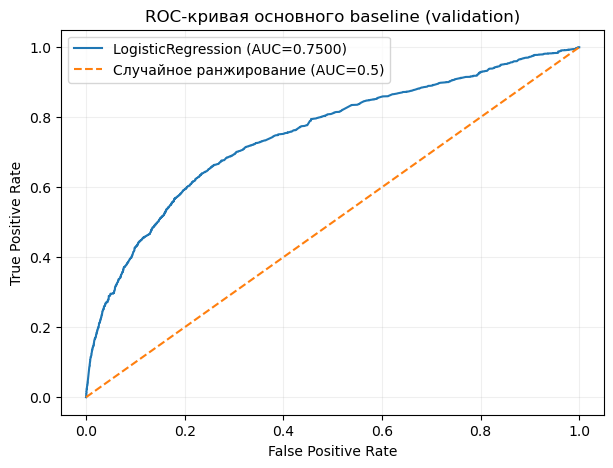

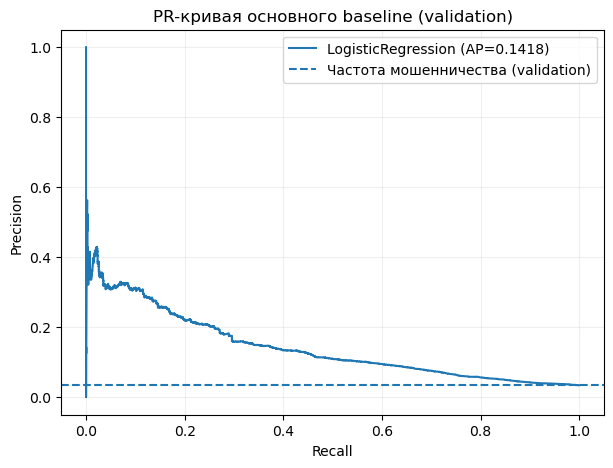

In [18]:
fpr, tpr, _ = roc_curve(y_val, p_baseline)
precision, recall, _ = precision_recall_curve(y_val, p_baseline)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"LogisticRegression (AUC={roc_auc_score(y_val, p_baseline):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Случайное ранжирование (AUC=0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая основного baseline (validation)")
plt.legend()
plt.grid(alpha=0.2)
plt.savefig(OUTPUT_DIR / "baseline_roc.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"LogisticRegression (AP={average_precision_score(y_val, p_baseline):.4f})")
plt.axhline(y_val.mean(), linestyle="--", label="Частота мошенничества (validation)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая основного baseline (validation)")
plt.legend()
plt.grid(alpha=0.2)
plt.savefig(OUTPUT_DIR / "baseline_pr.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.6. Анализ ошибок при ограниченной ёмкости проверки

Для демонстрации операционной интерпретации вводится **заранее фиксированное** правило: на дополнительную проверку направляется 1% транзакций с наибольшим предсказанным риском. Это не обучение порога на целевой переменной и не изменение основного протокола оценки. Дополнительные показатели:

- `Precision@1%` — доля мошеннических транзакций среди 1% отобранных;
- `Recall@1%` — доля всех мошеннических транзакций, попавших в отбор;
- количество ложных срабатываний (FP) и пропусков мошенничества (FN).

Для содержательного анализа отображаются три примера с высокой вероятностью среди ложных срабатываний и три пропущенных мошеннических транзакции с низкой оценкой риска. Отбор примеров служит иллюстрацией поведения модели и не доказывает причин ошибки.


In [19]:
TOP_FRACTION = 0.01  # Правило задано до анализа ошибок.
k = max(1, int(np.ceil(TOP_FRACTION * len(y_val))))

# Стабильная сортировка при совпадающих вероятностях.
ranked_positions = np.argsort(-p_baseline, kind="mergesort")
flagged = np.zeros(len(y_val), dtype=bool)
flagged[ranked_positions[:k]] = True

true_negative, false_positive, false_negative, true_positive = confusion_matrix(
    y_val, flagged.astype(int), labels=[0, 1]
).ravel()

precision_at_k = true_positive / k
recall_at_k = true_positive / int(y_val.sum())

print(f"Объём проверки: {k} из {len(y_val)} ({TOP_FRACTION:.1%})")
print(f"Precision@1%: {precision_at_k:.4f}")
print(f"Recall@1%: {recall_at_k:.4f}")
print(f"TP={true_positive}, FP={false_positive}, FN={false_negative}, TN={true_negative}")

# Для интерпретации сохраняются только агрегированные шаблоны ошибок.
# Отдельные TransactionID, временные метки, адреса и построчные оценки не публикуются.
error_table = val_df.loc[:, ["ProductCD", "card4", "card6"]].copy()
error_table["actual"] = y_val
error_table["predicted_risk"] = p_baseline
error_table["flagged_top_1pct"] = flagged

fp_subset = error_table.loc[
    (error_table["actual"] == 0) & error_table["flagged_top_1pct"]
].copy()
fn_subset = error_table.loc[
    (error_table["actual"] == 1) & (~error_table["flagged_top_1pct"])
].copy()

for name, subset in [("Ложные срабатывания (FP)", fp_subset),
                     ("Пропущенное мошенничество (FN)", fn_subset)]:
    patterns = (
        subset.groupby(["ProductCD", "card4", "card6"], dropna=False)
        .agg(
            n=("actual", "size"),
            median_risk=("predicted_risk", "median"),
        )
        .query("n >= 3")
        .sort_values("n", ascending=False)
        .head(3)
        .reset_index()
    )
    print(name, "— частые сочетания признаков (группы не менее 3 наблюдений):")
    display(patterns)

# Характерные ошибки описаны в Markdown-ячейке 10.8.
# Агрегированные шаблоны предназначены для публичной версии исследования.


Объём проверки: 1182 из 118108 (1.0%)
Precision@1%: 0.3071
Recall@1%: 0.0893
TP=363, FP=819, FN=3701, TN=113225
Ложные срабатывания (FP) — частые сочетания признаков (группы не менее 3 наблюдений):


,ProductCD,card4,card6,n,median_risk
0,C,visa,credit,544,0.248894
1,C,mastercard,credit,231,0.248674
2,C,visa,debit,11,0.224559


Пропущенное мошенничество (FN) — частые сочетания признаков (группы не менее 3 наблюдений):


,ProductCD,card4,card6,n,median_risk
0,W,visa,debit,979,0.017175
1,C,visa,debit,431,0.107414
2,W,visa,credit,321,0.043808


### 10.7. Сохранение результатов baseline

В каталог `results/` сохраняются агрегированные метрики и два графика. Обученная модель сохраняется локально в `artifacts/` для воспроизводимости оценок в рамках установленной версии scikit-learn. Модель и исходные данные **не следует** автоматически включать в Git: для воспроизведения сдаваемого результата нужны код, параметры и инструкции запуска.

Значения гипотезы, интерпретацию ROC-AUC/AP, характерные ошибки и ограничения необходимо зафиксировать в Markdown-ячейке **после фактического выполнения** указанных расчётов.



In [20]:
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_table.to_csv(OUTPUT_DIR / "baseline_metrics.csv", index=False)
joblib.dump(baseline_model, ARTIFACTS_DIR / "baseline_logreg.joblib")

experiment_summary = {
    "task": "IEEE-CIS Fraud Detection",
    "split": {
        "method": "chronological_holdout",
        "time_field": "TransactionDT",
        "cutoff": float(CUTOFF_DT),
        "train_rows": int(len(train_df)),
        "validation_rows": int(len(val_df)),
    },
    "features": BASELINE_FEATURES,
    "preprocessing": "median -> log1p -> scaling; categorical constant impute -> one-hot",
    "model": "LogisticRegression(solver=liblinear, L2 (default), C=1.0, max_iter=300)",
    "seed": SEED,
    "software": {
        "python": platform.python_version(),
        "scikit_learn": sklearn_version,
        "pandas": pd.__version__,
    },
    "metrics": {
        row["model"]: {
            "roc_auc": float(row["ROC-AUC"]),
            "average_precision": float(row["AP"]),
        }
        for _, row in metrics_table.iterrows()
    },
    "top_fraction": TOP_FRACTION,
    "precision_at_top_fraction": float(precision_at_k),
    "recall_at_top_fraction": float(recall_at_k),
    "false_positive_at_top_fraction": int(false_positive),
    "false_negative_at_top_fraction": int(false_negative),
}

with (OUTPUT_DIR / "baseline_summary.json").open("w", encoding="utf-8") as file:
    json.dump(experiment_summary, file, ensure_ascii=False, indent=2)

print("Сохранены:")
for path in [
    OUTPUT_DIR / "baseline_metrics.csv",
    OUTPUT_DIR / "baseline_summary.json",
    OUTPUT_DIR / "baseline_roc.png",
    OUTPUT_DIR / "baseline_pr.png",
    ARTIFACTS_DIR / "baseline_logreg.joblib",
]:
    print(" -", path)

Сохранены:
 - results\baseline_metrics.csv
 - results\baseline_summary.json
 - results\baseline_roc.png
 - results\baseline_pr.png
 - artifacts\baseline_logreg.joblib



### 10.8. Результаты и интерпретация baseline

**Условия эксперимента.**

На хронологически разделённой выборке выполнено сравнение константной модели `DummyClassifier(strategy="prior")` и логистической регрессии с L2-регуляризацией.

Основной baseline использует пять признаков: `TransactionAmt`, `ProductCD`, `card4`, `card6`, `P_emaildomain`. Числовой признак преобразуется с использованием медианной импутации, `log1p` и стандартизации. Для категориальных признаков применяются заполнение пропусков и One-Hot Encoding. Все обучаемые преобразования выполняются только на train.

Размер обучающей выборки — 472 432 транзакции, валидационной — 118 108 транзакций. Доля мошеннических операций на validation составляет 3,44%.

**Результаты локальной валидации.**

| Модель | ROC-AUC | Average Precision |
|---|---:|---:|
| DummyClassifier (prior) | 0,5000 | 0,0344 |
| LogisticRegression | 0,7500 | 0,1418 |

Логистическая регрессия превосходит константную модель по обеим метрикам. Прирост ROC-AUC составляет приблизительно 0,25. Average Precision превышает базовую распространённость положительного класса примерно в 4,1 раза.

Таким образом, выбранные транзакционные признаки содержат информацию, позволяющую ранжировать операции по риску мошенничества.

**Оценка при ограниченном объёме проверок.**

При отборе 1% транзакций с наибольшим предсказанным риском получены следующие результаты:

- Количество отобранных транзакций: 1 182.
- True Positive: 363.
- False Positive: 819.
- False Negative: 3 701.
- True Negative: 113 225.
- Precision@1%: 0,3071.
- Recall@1%: 0,0893.

Среди отобранных операций доля мошенничества составляет 30,71%, что существенно превышает распространённость положительного класса в валидационной выборке (3,44%).

В то же время при данном ограничении объёма проверок обнаруживается только 8,93% мошеннических транзакций. Следовательно, модель обладает некоторой способностью концентрировать мошеннические операции в верхней части ранжирования, но её эффективность при небольшом бюджете проверок остаётся ограниченной.

**Анализ характерных ошибок.**

Для локально рассмотренных наблюдений выявлены три показательных шаблона (без публикации идентификаторов и полных строк):

| Тип | Сочетание признаков | Оценка риска | Характер ошибки |
|---|---|---:|---|
| FP | `C / mastercard / credit` | ≈ 0,59 | Немошенническая операция получила высокий риск |
| FP | `W / visa / credit` | ≈ 0,58 | Высокая оценка не означала подтверждённое мошенничество |
| FN | `W / mastercard / debit` | ≈ 0,0002 | Мошеннические операции с совпадающими пятью признаками получили очень низкий риск |

Последний шаблон показывает ограничение пятипризнакового представления: объекты с идентичными входными значениями неразличимы для модели. Эти отдельные примеры не заменяют агрегированного анализа ошибок.

**Ограничения исследования.**

1. Используется небольшой набор из пяти транзакционных признаков без дополнительных сведений об устройстве.
2. Первоначальная оценка основана на одном хронологическом holdout; дополнительные проверки временной изменчивости выполнены отдельно в разделе 11.
3. Полученные оценки вероятностей не проверены на калибровку.
4. Анонимизация и неполное описание происхождения признаков ограничивают проверку их доступности в момент предсказания.
5. Не учитываются экономические последствия ложноположительных и ложноотрицательных решений.

**Вывод.**

Предварительная гипотеза о превосходстве логистической регрессии над константным baseline подтверждена на выбранной локальной валидации.

Полученные показатели являются исходной точкой для дальнейших исследований, но не подтверждают готовность модели к промышленному применению.

Следующими направлениями после фиксации исходного baseline стали проверка временной устойчивости (раздел 11) и отдельная абляция признаков `identity` (раздел 13).


## 11. Анализ временной устойчивости baseline

**Исследовательский вопрос.** Насколько различаются ROC-AUC и Average Precision при оценке модели на разных временных интервалах?

Оценка состоит из двух частей:

1. **Диагностика зафиксированного `baseline_v1` на неделях основной validation:** модель не переобучается. Рассчитываются метрики для временных срезов одного и того же отложенного периода.
2. **Три внутренних expanding-window разбиения в train:** для каждого разбиения создаётся новая копия pipeline, обучаемая только на более ранних данных. Временные блоки проверки не перекрываются.

Главная validation из раздела 10 не используется для выбора параметров или признаков. Анализ недель её периода носит **диагностический характер**. Результаты внутренних разбиений предназначены для оценки временной изменчивости и последующего сравнения исследовательских решений. Среднее и стандартное отклонение по временным блокам не следует интерпретировать как оценку независимых повторений эксперимента.


### 11.1. Метрики baseline по неделям отложенной validation

Временные срезы определяются по `TransactionDT` относительно первого наблюдения validation. Для каждого среза рассчитываются число транзакций, число и доля мошеннических операций, ROC-AUC и AP. При отсутствии одного из классов ROC-AUC не вычисляется. Первая или последняя неделя могут быть неполными.

Изменения AP следует рассматривать вместе с распространённостью мошенничества, поскольку AP чувствительна к дисбалансу классов. Разбиение выполняется только после того, как модель уже зафиксирована: **для диагностического анализа используются существующие `y_val` и `p_baseline`**.


In [21]:
# Используются результаты из раздела 10; повторное обучение не требуется.
assert len(val_df) == len(y_val) == len(p_baseline)
assert np.array_equal(val_df["isFraud"].to_numpy(), y_val)
assert np.isfinite(p_baseline).all()

WEEK_SECONDS = 7 * 24 * 60 * 60
validation_week = (
    (val_df["TransactionDT"].to_numpy() - val_df["TransactionDT"].min())
    // WEEK_SECONDS
).astype(int)

weekly_records = []
for week in sorted(np.unique(validation_week)):
    mask = validation_week == week
    truth = y_val[mask]
    scores = p_baseline[mask]
    n_pos = int(truth.sum())
    n_neg = int(len(truth) - n_pos)
    has_both_classes = n_pos > 0 and n_neg > 0

    weekly_records.append({
        "validation_week": int(week),
        "n_transactions": int(mask.sum()),
        "n_fraud": n_pos,
        "fraud_rate": float(truth.mean()),
        "roc_auc": float(roc_auc_score(truth, scores)) if has_both_classes else np.nan,
        "average_precision": (
            float(average_precision_score(truth, scores)) if n_pos > 0 else np.nan
        ),
    })

validation_weekly_metrics = pd.DataFrame(weekly_records)
assert validation_weekly_metrics["n_transactions"].sum() == len(val_df)
assert validation_weekly_metrics["n_fraud"].sum() == int(y_val.sum())

display(validation_weekly_metrics.round(5))
print("Всего недельных срезов:", len(validation_weekly_metrics))
print("Недельных срезов с обоими классами:", validation_weekly_metrics["roc_auc"].notna().sum())

validation_weekly_metrics.to_csv(
    OUTPUT_DIR / "validation_weekly_metrics.csv", index=False
)

,validation_week,n_transactions,n_fraud,fraud_rate,roc_auc,average_precision
0,0,18562,640,0.03448,0.72671,0.12912
1,1,21476,663,0.03087,0.76046,0.16321
2,2,19721,560,0.02840,0.71581,0.11478
3,3,21096,741,0.03513,0.75723,0.13165
4,4,19928,743,0.03728,0.75674,0.17412
5,5,17325,717,0.04139,0.77205,0.16574


Всего недельных срезов: 6
Недельных срезов с обоими классами: 6


### 11.2. Визуализация изменений качества во времени

Строятся два независимых графика. На первом отображается ROC-AUC по неделям validation. На втором сравниваются AP и базовая доля мошенничества в соответствующем периоде. Размеры недельных выборок учитываются при интерпретации: результаты на малом числе положительных примеров менее устойчивы.


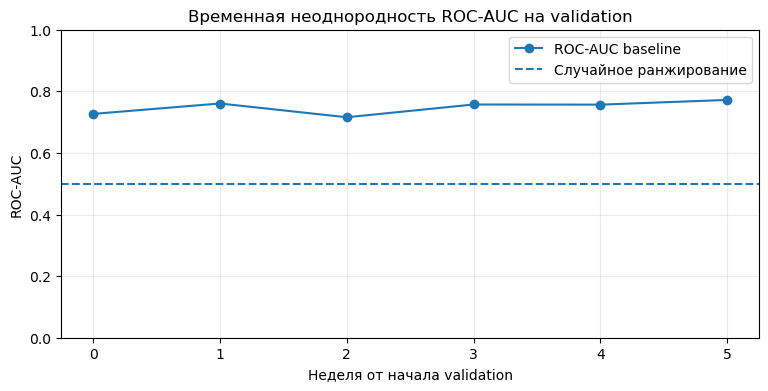

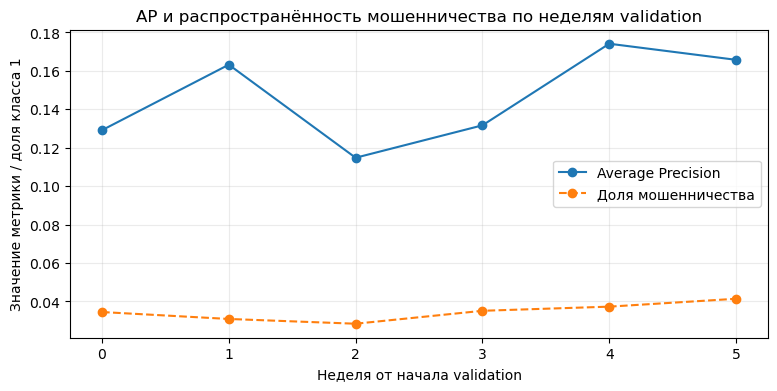

In [22]:
plt.figure(figsize=(9, 4))
plt.plot(
    validation_weekly_metrics["validation_week"],
    validation_weekly_metrics["roc_auc"],
    marker="o", label="ROC-AUC baseline",
)
plt.axhline(0.5, linestyle="--", label="Случайное ранжирование")
plt.xlabel("Неделя от начала validation")
plt.ylabel("ROC-AUC")
plt.title("Временная неоднородность ROC-AUC на validation")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.savefig(OUTPUT_DIR / "validation_weekly_roc_auc.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(
    validation_weekly_metrics["validation_week"],
    validation_weekly_metrics["average_precision"],
    marker="o", label="Average Precision",
)
plt.plot(
    validation_weekly_metrics["validation_week"],
    validation_weekly_metrics["fraud_rate"],
    marker="o", linestyle="--", label="Доля мошенничества",
)
plt.xlabel("Неделя от начала validation")
plt.ylabel("Значение метрики / доля класса 1")
plt.title("AP и распространённость мошенничества по неделям validation")
plt.grid(alpha=0.25)
plt.legend()
plt.savefig(OUTPUT_DIR / "validation_weekly_ap.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.3. Внутренняя временная проверка на трёх expanding-window разбиениях

Цель — оценить изменчивость baseline на последовательных периодах **без обращения к основной validation**. Границы задаются квантилями временной координаты исходной обучающей части: 40%, 60%, 80%. В каждом эксперименте обучение охватывает всё доступное прошлое, а проверка выполняется на следующем временном блоке:

| Эксперимент | Обучение | Локальная проверка |
|---|---|---|
| Fold 1 | первые ~40% train | следующие ~20% train |
| Fold 2 | первые ~60% train | следующие ~20% train |
| Fold 3 | первые ~80% train | последние ~20% train |

Временные интервалы проверки не перекрываются; интервалы обучения закономерно пересекаются. Границы получаются только из `TransactionDT`; `isFraud` при их выборе не используется. Транзакции с одинаковым временем попадают в одну часть каждого fold.

Во всех трёх экспериментах используется **точно та же модель с теми же пятью признаками и параметрами**, что в разделе 10. Вызов `clone(baseline_model)` создаёт необученную модель; все значения для импутации и кодирования вычисляются заново только по локальной train-части.


In [23]:
from sklearn.base import clone

# Отдельно используются только транзакции из исходной train-части.
internal_time = train_df["TransactionDT"]
fold_boundaries = internal_time.quantile([0.4, 0.6, 0.8]).to_numpy(dtype=float)
assert np.all(np.diff(fold_boundaries) > 0), "Временные границы совпали"

fold_records = []
fold_limits = [
    (fold_boundaries[0], fold_boundaries[1]),
    (fold_boundaries[1], fold_boundaries[2]),
    (fold_boundaries[2], np.inf),
]

for fold_id, (train_time_end, val_time_end) in enumerate(fold_limits, start=1):
    fit_mask = (internal_time < train_time_end).to_numpy()
    check_mask = (
        ((internal_time >= train_time_end) & (internal_time < val_time_end)).to_numpy()
    )

    fold_train = train_df.loc[fit_mask]
    fold_validation = train_df.loc[check_mask]

    assert len(fold_train) > 0 and len(fold_validation) > 0
    assert fold_train["TransactionDT"].max() < fold_validation["TransactionDT"].min()
    assert fold_validation["TransactionDT"].max() < val_df["TransactionDT"].min()

    y_fit = fold_train["isFraud"].astype(int).to_numpy()
    y_check = fold_validation["isFraud"].astype(int).to_numpy()
    assert np.unique(y_fit).size == 2 and np.unique(y_check).size == 2

    fold_model = clone(baseline_model)
    fold_model.fit(fold_train[BASELINE_FEATURES], y_fit)
    scores = fold_model.predict_proba(fold_validation[BASELINE_FEATURES])[:, 1]

    fold_records.append({
        "fold": fold_id,
        "train_rows": len(fold_train),
        "validation_rows": len(fold_validation),
        "train_time_max": float(fold_train["TransactionDT"].max()),
        "validation_time_min": float(fold_validation["TransactionDT"].min()),
        "validation_time_max": float(fold_validation["TransactionDT"].max()),
        "validation_fraud_count": int(y_check.sum()),
        "validation_fraud_rate": float(y_check.mean()),
        "roc_auc": float(roc_auc_score(y_check, scores)),
        "average_precision": float(average_precision_score(y_check, scores)),
        "dummy_roc_auc": 0.5,
        "dummy_ap": float(y_check.mean()),
    })
    print(f"Fold {fold_id}: ",
          f"train={len(fold_train):,}; val={len(fold_validation):,}; ",
          f"ROC-AUC={fold_records[-1]['roc_auc']:.4f}; ",
          f"AP={fold_records[-1]['average_precision']:.4f}")

# Дублирование недель между локальными блоками оценки не допускается.
fold_metrics = pd.DataFrame(fold_records)
assert len(fold_metrics) == 3
assert fold_metrics["validation_rows"].sum() <= len(train_df)

print("\nРезультаты expanding-window проверки:")
display(fold_metrics.round(5))
fold_metrics.to_csv(OUTPUT_DIR / "temporal_cv_results.csv", index=False)

Fold 1:  train=188,973; val=94,486;  ROC-AUC=0.7347;  AP=0.1369
Fold 2:  train=283,459; val=94,486;  ROC-AUC=0.7402;  AP=0.1105
Fold 3:  train=377,945; val=94,487;  ROC-AUC=0.7738;  AP=0.1763

Результаты expanding-window проверки:


,fold,train_rows,validation_rows,train_time_max,validation_time_min,validation_time_max,validation_fraud_count,validation_fraud_rate,roc_auc,average_precision,dummy_roc_auc,dummy_ap
0,1,188973,94486,4222356.0,4222358.0,6918131.0,4032,0.04267,0.73466,0.13693,0.5,0.04267
1,2,283459,94486,6918131.0,6918138.0,9466264.0,3385,0.03583,0.74017,0.11045,0.5,0.03583
2,3,377945,94487,9466264.0,9466279.0,12192842.0,3704,0.03920,0.77377,0.17625,0.5,0.03920


### 11.4. Сводная статистика и интерпретация временной изменчивости

Рассчитываются **среднее и выборочное стандартное отклонение** (`ddof=1`) по трём непересекающимся временным блокам проверки. Указанное стандартное отклонение отражает **различия между периодами** при разном объёме предшествующего обучения. Это не доверительный интервал и не независимые повторы одного и того же обучающего процесса.

Сопоставление с результатом `baseline_v1` на внешней validation приводится только для справки. На основании этих значений нельзя подбирать новую модель по уже раскрытому holdout.


,metric,mean,std_sample,min,max
0,ROC-AUC,0.74953,0.02117,0.73466,0.77377
1,Average Precision,0.14121,0.03311,0.11045,0.17625


Основной holdout, ROC-AUC: 0.74998
Основной holdout, AP: 0.14182


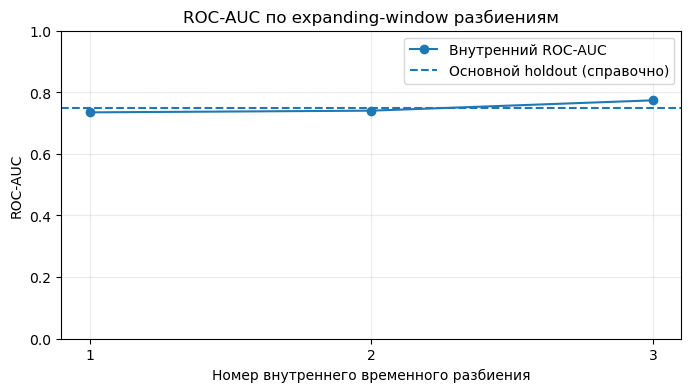

Сохранены результаты временной проверки:
 - results\validation_weekly_metrics.csv
 - results\validation_weekly_roc_auc.png
 - results\validation_weekly_ap.png
 - results\temporal_cv_results.csv
 - results\temporal_cv_summary.csv
 - results\temporal_cv_summary.json
 - results\temporal_cv_roc_auc.png


In [24]:
fold_summary = pd.DataFrame({
    "metric": ["ROC-AUC", "Average Precision"],
    "mean": [fold_metrics["roc_auc"].mean(), fold_metrics["average_precision"].mean()],
    "std_sample": [
        fold_metrics["roc_auc"].std(ddof=1),
        fold_metrics["average_precision"].std(ddof=1),
    ],
    "min": [fold_metrics["roc_auc"].min(), fold_metrics["average_precision"].min()],
    "max": [fold_metrics["roc_auc"].max(), fold_metrics["average_precision"].max()],
})

display(fold_summary.round(5))
print("Основной holdout, ROC-AUC:", f"{roc_auc_score(y_val, p_baseline):.5f}")
print("Основной holdout, AP:", f"{average_precision_score(y_val, p_baseline):.5f}")

plt.figure(figsize=(8, 4))
plt.plot(fold_metrics["fold"], fold_metrics["roc_auc"], marker="o", label="Внутренний ROC-AUC")
plt.axhline(roc_auc_score(y_val, p_baseline), linestyle="--", label="Основной holdout (справочно)")
plt.xticks(fold_metrics["fold"])
plt.ylim(0, 1)
plt.xlabel("Номер внутреннего временного разбиения")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC по expanding-window разбиениям")
plt.legend()
plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "temporal_cv_roc_auc.png", dpi=150, bbox_inches="tight")
plt.show()

# Сохраняется только агрегированная статистика; модели фолдов не публикуются.
fold_summary.to_csv(OUTPUT_DIR / "temporal_cv_summary.csv", index=False)
with (OUTPUT_DIR / "temporal_cv_summary.json").open("w", encoding="utf-8") as file:
    json.dump({
        "method": "3 expanding-window folds on original train only",
        "train_quantiles_for_boundaries": [0.4, 0.6, 0.8],
        "features": list(BASELINE_FEATURES),
        "folds": fold_metrics.to_dict(orient="records"),
        "summary": fold_summary.to_dict(orient="records"),
    }, file, ensure_ascii=False, indent=2)

print("Сохранены результаты временной проверки:")
for name in [
    "validation_weekly_metrics.csv",
    "validation_weekly_roc_auc.png",
    "validation_weekly_ap.png",
    "temporal_cv_results.csv",
    "temporal_cv_summary.csv",
    "temporal_cv_summary.json",
    "temporal_cv_roc_auc.png",
]:
    print(" -", OUTPUT_DIR / name)

### 11.5. Дополнительная оценка неопределённости: bootstrap (необязательно)

Стратифицированное по объектам bootstrap-пересэмплирование позволяет получить **приближённый процентильный интервал** для ROC-AUC и AP на зафиксированной validation. Это оценка вариации из-за состава наблюдений **при допущении обменности транзакций внутри классов**. Она **не** учитывает временную зависимость, повторяющиеся сущности и сдвиг распределений между периодами. Поэтому такие интервалы нельзя интерпретировать как гарантии качества на будущих неделях.

Эта проверка вычислительно дополнительная и **не заменяет expanding-window анализ**. По умолчанию отключена; для её запуска установить `RUN_BOOTSTRAP = True`.


In [25]:
RUN_BOOTSTRAP = False
BOOTSTRAP_REPEATS = 200

if RUN_BOOTSTRAP:
    rng = np.random.default_rng(SEED)
    positions_0 = np.flatnonzero(y_val == 0)
    positions_1 = np.flatnonzero(y_val == 1)
    bootstrap_scores = []

    for iteration in range(BOOTSTRAP_REPEATS):
        sample_0 = rng.choice(positions_0, size=len(positions_0), replace=True)
        sample_1 = rng.choice(positions_1, size=len(positions_1), replace=True)
        positions = np.concatenate([sample_0, sample_1])
        bootstrap_scores.append({
            "iteration": iteration + 1,
            "roc_auc": roc_auc_score(y_val[positions], p_baseline[positions]),
            "average_precision": average_precision_score(
                y_val[positions], p_baseline[positions]
            ),
        })

    bootstrap_results = pd.DataFrame(bootstrap_scores)
    bootstrap_interval = bootstrap_results[["roc_auc", "average_precision"]].quantile(
        [0.025, 0.975]
    )
    display(bootstrap_interval.round(5))
    bootstrap_results.to_csv(OUTPUT_DIR / "bootstrap_results.csv", index=False)
    bootstrap_interval.to_csv(OUTPUT_DIR / "bootstrap_percentile_interval.csv")
else:
    print("Bootstrap не выполнялся: RUN_BOOTSTRAP=False.")

Bootstrap не выполнялся: RUN_BOOTSTRAP=False.


### 11.6. Выводы по временной устойчивости baseline

**Диагностика по неделям основной validation.** Для шести последовательных недель ROC-AUC изменяется от 0,71581 до 0,77205. На всех неделях он выше уровня случайного ранжирования (0,5). Average Precision меняется от 0,11478 до 0,17412; одновременно доля мошенничества изменяется от 2,84% до 4,14%. Таким образом, изменение AP необходимо рассматривать совместно с распространённостью положительного класса.

**Повторная временная проверка внутри train.** На трёх expanding-window разбиениях получены значения ROC-AUC 0,73466; 0,74017 и 0,77377. Среднее составляет 0,74953 при выборочном стандартном отклонении 0,02117. Для Average Precision получены 0,13693; 0,11045 и 0,17625 (среднее 0,14121, стандартное отклонение 0,03311).

Метрики исходного holdout (ROC-AUC = 0,74998; AP = 0,14182) находятся внутри диапазонов значений, наблюдаемых на внутренних фолдах. Это не даёт оснований считать первоначальную оценку исключительно аномальной; в то же время совпадение средних не доказывает стабильности будущего качества. Поскольку обучающие окна пересекаются, а временные периоды различаются по составу и доле мошенничества, статистику `mean ± std` нельзя интерпретировать как доверительный интервал.

**Вывод по исследовательскому вопросу.** Различающая способность простой логистической регрессии сохраняется на исследованных временных периодах, однако результаты неоднородны, особенно по Average Precision. Для проверки применимости в реальной антифрод-системе необходимы дополнительные данные о происхождении признаков, об изменении распределений и о стоимости ошибок.

**Статус дополнительных оценок.** Bootstrap не выполнялся (`RUN_BOOTSTRAP = False`). На данном этапе он не требуется для воспроизведения baseline; стандартный объектный bootstrap без учёта возможных временных зависимостей не использован для статистической точности.


## 12. Воспроизводимость через независимые скрипты

Цель этапа — обеспечить повторное обучение и оценку baseline без ручного выполнения ячеек Jupyter. Параметры эксперимента фиксируются в `configs/baseline.json`, сборка pipeline и загрузка данных — в `src/utils.py`, обучение — в `src/train.py`, оценка — в `src/evaluate.py`.

Воспроизводимый эксперимент должен использовать тот же хронологический split, те же пять признаков и предобработку, что и `baseline_v1`. Ожидается совпадение ROC-AUC и AP с результатами ноутбука в пределах погрешности округления.

Скрипты выполняются из корня проекта, в котором располагается ZIP-архив. Папка `src`, каталог `configs` и файлы `.bat`/`.sh` размещаются рядом с ноутбуком.


In [26]:
from pathlib import Path

project_root = Path.cwd()
required_project_files = [
    "configs/baseline.json",
    "src/__init__.py",
    "src/utils.py",
    "src/train.py",
    "src/evaluate.py",
    "scripts/run_baseline.bat",
    "requirements.txt",
]

for relative_path in required_project_files:
    path = project_root / relative_path
    print(f"{'OK' if path.is_file() else 'НЕ НАЙДЕН'}: {relative_path}")

assert all((project_root / p).is_file() for p in required_project_files)

OK: configs/baseline.json
OK: src/__init__.py
OK: src/utils.py
OK: src/train.py
OK: src/evaluate.py
OK: scripts/run_baseline.bat
OK: requirements.txt


### 12.1. Сопоставление результатов независимого запуска

Скрипты запускаются в той же среде Python, что используется ядром Jupyter. После выполнения сравниваются результаты `baseline_v1` из ноутбука и независимого запуска. При отсутствии совпадения необходимо проверить источник данных, версию scikit-learn, границу времени, признаки и параметры модели.

Повторный запуск управляется переменной `RUN_INDEPENDENT_REPRODUCTION`. При значении `True` обучение и оценка выполняются заново, а локальная модель и `results/baseline_metrics.csv` перезаписываются. Независимое воспроизведение на исходном архиве уже выполнено; результат зафиксирован ниже.


In [27]:
import json
import subprocess
import sys

RUN_INDEPENDENT_REPRODUCTION = True

if RUN_INDEPENDENT_REPRODUCTION:
    for module in ("src.train", "src.evaluate"):
        subprocess.run(
            [sys.executable, "-m", module, "--config", "configs/baseline.json"],
            cwd=Path.cwd(),
            check=True,
        )

    with (OUTPUT_DIR / "baseline_script_summary.json").open("r", encoding="utf-8") as stream:
        script_metrics = json.load(stream)

    notebook_auc = float(roc_auc_score(y_val, p_baseline))
    notebook_ap = float(average_precision_score(y_val, p_baseline))

    comparison = pd.DataFrame([
        {"metric": "ROC-AUC", "notebook": notebook_auc,
         "script": script_metrics["roc_auc"]},
        {"metric": "Average Precision", "notebook": notebook_ap,
         "script": script_metrics["average_precision"]},
    ])
    comparison["absolute_difference"] = (
        comparison["notebook"] - comparison["script"]
    ).abs()
    display(comparison)

    # Допуск учитывает малые численные различия между окружениями.
    assert (comparison["absolute_difference"] < 1e-4).all(), (
        "Результаты скриптов и ноутбука существенно различаются."
    )
    print("Проверка независимого воспроизведения пройдена.")
else:
    print("Воспроизведение отключено. Измените RUN_INDEPENDENT_REPRODUCTION на True.")

,metric,notebook,script,absolute_difference
0,ROC-AUC,0.749975,0.749975,0.0
1,Average Precision,0.141819,0.141819,0.0


Проверка независимого воспроизведения пройдена.


### 12.2. Результат проверки воспроизводимости

Независимые скрипты `src.train` и `src.evaluate` были запущены на исходном локальном архиве с теми же параметрами, что и исследовательский ноутбук.

| Метрика | Ноутбук | Независимый скрипт | Абсолютное расхождение |
|---|---:|---:|---:|
| ROC-AUC | 0,749975 | 0,749975 | 0,000000 |
| Average Precision | 0,141819 | 0,141819 | 0,000000 |

**Результат.** Совпадение при отображаемой точности подтверждает воспроизводимость исходного baseline в проверенном локальном окружении. При запуске использовалась `scikit-learn==1.4.2`. Факт совпадения не означает проверки на всех возможных версиях Python или в полностью чистой среде.

Основной эксперимент сохраняется как `baseline_v1`. Выбор признаков для последующей абляции выполняется отдельно на внутренних временных разбиениях и не изменяет метрики исходного holdout.


## 13. Проверка вклада дополнительных признаков `identity`

**Исследовательский вопрос H2.** Улучшает ли добавление сведений о доступности записи `identity` и характеристик устройства качество ранжирования мошеннических транзакций по сравнению с пятью исходными признаками логистической регрессии?

Проверяются три заранее зафиксированных варианта: **A** — исходные пять транзакционных признаков; **B** — те же признаки и индикатор наличия записи `identity`; **C** — вариант B с дополнительными категориальными полями `DeviceType`, `id_12`, `id_15`, `id_31`. Поля `DeviceInfo` и `id_33` не включаются в первый эксперимент из-за сравнительно высокой кардинальности и большого числа пропусков. `TransactionID`, `TransactionDT` и `isFraud` не используются в качестве входов моделей.

**Контролируемые условия:** один алгоритм `LogisticRegression` с теми же гиперпараметрами, одинаковая предобработка, три идентичных expanding-window разбиения внутри исходного train (границы 40%, 60%, 80%). В каждом фолде заново обучаются преобразования и классификатор. Основная validation из 118 108 транзакций исключена из экспериментального подбора признаков.

Основной критерий — разница среднего ROC-AUC по трём фолдам относительно варианта A. Дополнительно сравниваются AP и качество отбора 1% наиболее рискованных операций. Разница метрик по трём фолдам носит описательный характер: фолды зависимы, статистический тест значимости не проводится.

**Особое ограничение:** наличие записи `identity` может быть связано с механизмом сбора данных. Даже положительный результат не подтверждает, что этот индикатор доступен в момент авторизации и пригоден для промышленной модели.


In [28]:
# Проверка доступности исходных признаков эксперимента.
from pathlib import Path
import json

required_identity = ["has_identity", "DeviceType", "id_12", "id_15", "id_31"]
assert set(required_identity).issubset(train_df.columns)
assert len(train_df) == 472_432, "Изменился ранее зафиксированный train."
assert len(val_df) == 118_108, "Изменился основной holdout."

for relative_path in ["configs/identity_ablation.json", "src/identity_ablation.py"]:
    assert Path(relative_path).is_file(), f"Отсутствует файл: {relative_path}"

with Path("configs/identity_ablation.json").open(encoding="utf-8") as f:
    identity_experiment_config = json.load(f)

print("Признаки identity:", identity_experiment_config["identity_features"])
print("Доля наблюдений с identity на исходном train:",
      f"{train_df['has_identity'].mean():.2%}")

Признаки identity: ['DeviceType', 'id_12', 'id_15', 'id_31']
Доля наблюдений с identity на исходном train: 25.50%


### 13.1. Запуск контролируемого сравнения

Расчёты выполняются через общую функцию `run_ablation` из `src/identity_ablation.py`. Это устраняет расхождение между кодом ноутбука и независимым консольным запуском. Результаты основного holdout не используются для выбора признакового набора.

Варианты A, B, C оцениваются на одних и тех же транзакциях каждого внутреннего фолда. Прирост качества интерпретируется как изменение метрики при добавлении признаков, а не как доказательство причинной связи.


In [29]:
from src.utils import load_config
from src.identity_ablation import run_ablation, save_results

baseline_cfg = load_config("configs/baseline.json")

identity_folds, identity_summary = run_ablation(
    train_df=train_df,
    baseline_config=baseline_cfg,
    experiment_config=identity_experiment_config,
)

display(identity_folds.round(5))
display(identity_summary.round(5))

Fold 1, A_transaction_only: ROC-AUC=0.73466, AP=0.13693, Precision@1%=0.2825
Fold 1, B_plus_identity_status: ROC-AUC=0.73543, AP=0.14039, Precision@1%=0.2899
Fold 1, C_plus_identity_fields: ROC-AUC=0.73128, AP=0.18056, Precision@1%=0.3905
Fold 2, A_transaction_only: ROC-AUC=0.74017, AP=0.11045, Precision@1%=0.1778
Fold 2, B_plus_identity_status: ROC-AUC=0.74171, AP=0.11310, Precision@1%=0.1746
Fold 2, C_plus_identity_fields: ROC-AUC=0.74984, AP=0.13536, Precision@1%=0.3037
Fold 3, A_transaction_only: ROC-AUC=0.77377, AP=0.17625, Precision@1%=0.3492
Fold 3, B_plus_identity_status: ROC-AUC=0.77482, AP=0.17906, Precision@1%=0.3534
Fold 3, C_plus_identity_fields: ROC-AUC=0.77643, AP=0.20699, Precision@1%=0.4339


,fold,variant,train_rows,validation_rows,validation_fraud_count,validation_fraud_rate,roc_auc,average_precision,precision_at_1pct,recall_at_1pct
0,1,A_transaction_only,188973,94486,4032,0.04267,0.73466,0.13693,0.28254,0.06622
1,1,B_plus_identity_status,188973,94486,4032,0.04267,0.73543,0.14039,0.28995,0.06796
2,1,C_plus_identity_fields,188973,94486,4032,0.04267,0.73128,0.18056,0.39048,0.09152
3,2,A_transaction_only,283459,94486,3385,0.03583,0.74017,0.11045,0.17778,0.04963
4,2,B_plus_identity_status,283459,94486,3385,0.03583,0.74171,0.11310,0.17460,0.04874
5,2,C_plus_identity_fields,283459,94486,3385,0.03583,0.74984,0.13536,0.30370,0.08479
6,3,A_transaction_only,377945,94487,3704,0.03920,0.77377,0.17625,0.34921,0.08909
7,3,B_plus_identity_status,377945,94487,3704,0.03920,0.77482,0.17906,0.35344,0.09017
8,3,C_plus_identity_fields,377945,94487,3704,0.03920,0.77643,0.20699,0.43386,0.11069


,variant,roc_auc_mean,roc_auc_std,ap_mean,ap_std,precision_at_1pct_mean,recall_at_1pct_mean,delta_roc_auc_vs_A,delta_ap_vs_A
0,A_transaction_only,0.74953,0.02117,0.14121,0.03311,0.26984,0.06831,0.00000,0.00000
1,B_plus_identity_status,0.75065,0.02117,0.14419,0.03315,0.27266,0.06896,0.00112,0.00297
2,C_plus_identity_fields,0.75252,0.02269,0.17430,0.03622,0.37601,0.09566,0.00299,0.03309


### 13.2. Контроль сопоставимости исходного baseline

Вариант A должен воспроизводить ROC-AUC и AP трёх внутренних фолдов из раздела 11 с допуском на численные вычисления. Таким образом проверяется, что эксперимент по добавлению признаков не изменил временные разбиения и исходные условия сравнения.


In [30]:
# Внутренние метрики из раздела 11 проверяются на точное соответствие
# значениям контрольного варианта A в новом эксперименте.
reference = fold_metrics.set_index("fold")
control = identity_folds.loc[
    identity_folds["variant"] == "A_transaction_only"
].set_index("fold")

import numpy as np
for new_name, old_name in [("roc_auc", "roc_auc"),
                           ("average_precision", "average_precision")]:
    differences = (control[new_name] - reference[old_name]).abs()
    print(new_name, "максимальное расхождение:", float(differences.max()))
    assert np.allclose(control[new_name], reference[old_name], rtol=0, atol=1e-4)

print("Контрольный вариант A согласован с временной валидацией раздела 11.")

roc_auc максимальное расхождение: 0.0
average_precision максимальное расхождение: 0.0
Контрольный вариант A согласован с временной валидацией раздела 11.


### 13.3. Сохранение результатов и визуализация

Публикуются только агрегированные метрики и графики по фолдам. Сведения об отдельных транзакциях и их предсказания не сохраняются. Результат эксперимента не заменяет `baseline_v1`: исходная модель и её показатели на основном holdout остаются зафиксированными.


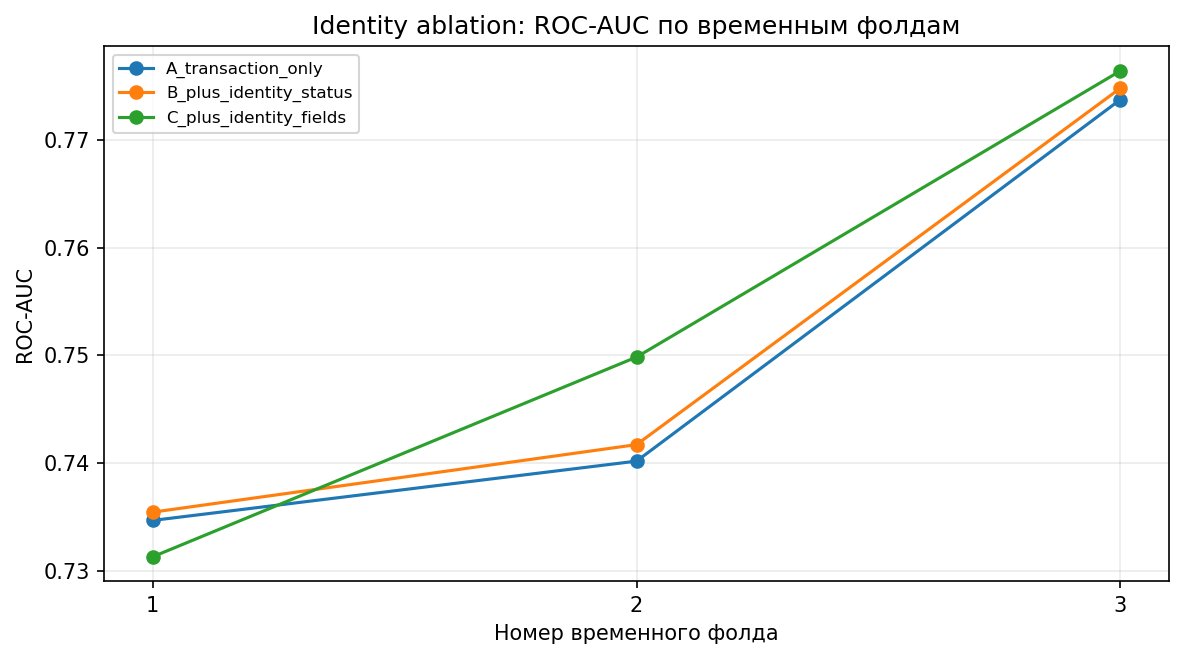

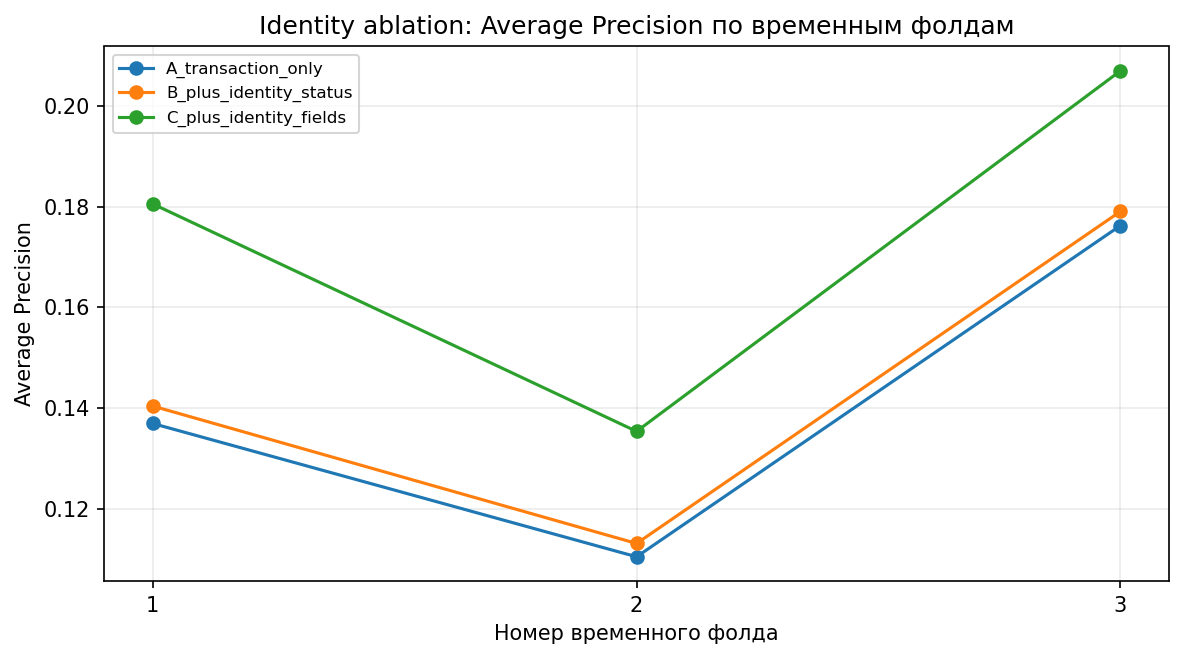

Созданы:
 - results\identity_ablation_ap.png
 - results\identity_ablation_folds.csv
 - results\identity_ablation_protocol.json
 - results\identity_ablation_roc_auc.png
 - results\identity_ablation_summary.csv


In [31]:
from IPython.display import Image, display

ablation_output = save_results(
    identity_folds, identity_summary, identity_experiment_config
)

for filename in ["identity_ablation_roc_auc.png", "identity_ablation_ap.png"]:
    display(Image(filename=str(ablation_output / filename)))

print("Созданы:")
for path in sorted(ablation_output.glob("identity_ablation*")):
    print(" -", path)

### 13.4. Результаты и интерпретация абляции `identity`

На одинаковых трёх expanding-window разбиениях внутри исходной train-части сравнивались модели с одинаковыми алгоритмом, гиперпараметрами и протоколом предобработки. Основная внешняя validation не использовалась для выбора варианта.

| Вариант | Средний ROC-AUC ± std | Средний AP ± std | Средний Precision@1% | Средний Recall@1% |
|---|---:|---:|---:|---:|
| A: пять исходных признаков | 0,74953 ± 0,02117 | 0,14121 ± 0,03311 | 0,26984 | 0,06831 |
| B: A + наличие `identity` | 0,75065 ± 0,02117 | 0,14419 ± 0,03315 | 0,27266 | 0,06896 |
| C: B + четыре поля `identity` | 0,75252 ± 0,02269 | 0,17430 ± 0,03622 | 0,37601 | 0,09566 |

**Сравнение с исходным вариантом A.** Для B наблюдаемый средний прирост ROC-AUC составляет 0,00112, AP — 0,00297. Для C относительно A прирост составляет 0,00299 по ROC-AUC и 0,03309 по AP. Средний Precision@1% изменяется с 26,98% до 37,60%, Recall@1% — с 6,83% до 9,57%.

**Неоднородность эффекта.** При переходе от A к C ROC-AUC на первом фолде уменьшается с 0,73466 до 0,73128, на втором возрастает с 0,74017 до 0,74984, на третьем — с 0,77377 до 0,77643. Следовательно, улучшение ROC-AUC не наблюдается на всех временных периодах. Вместе с тем AP и показатели отбора наиболее рискованного 1% транзакций выше у C на каждом из трёх фолдов.

**Вывод относительно H2.** Добавление полей `identity` связано с улучшением AP и метрик отбора top-1% в исследованных временных интервалах. Увеличение среднего ROC-AUC невелико и неоднородно по фолдам. Полученный эффект не следует интерпретировать как статистически доказанное улучшение или подтверждение готовности полей к использованию в момент авторизации.

**Ограничения.** Разбиения являются последовательными и зависимыми; выборочное стандартное отклонение описывает разброс метрик, а не доверительный интервал. Механизм появления записи `identity` неизвестен, что допускает смещение, связанное с процессом сбора данных. Исходная модель `baseline_v1` на основном holdout остаётся без изменений. Дальнейшая проверка возможна на новом будущем периоде при подтверждённой доступности признаков и отдельно определённой операционной цели.


### 13.5. Воспроизводимый консольный запуск исследования

Независимый запуск из корня проекта:

```bat
python -m src.identity_ablation --config configs/identity_ablation.json
```

Скрипт повторно загружает необходимые столбцы из ZIP, соединяет таблицы по `TransactionID`, использует исходную временную границу и воспроизводит все три внутренних фолда. Поскольку Jupyter вызывает ту же исследовательскую функцию, логика расчётов общая.
